# EDA del panel

Análisis exploratorio (EDA) de `data/panel.csv`, que sale de `04_build_panel.ipynb`: una fila por empresa y trimestre calendario (2018Q1–2024Q4), con 11 conceptos en USD, 8 ratios en fracción y la fecha de quiebra. El rumbo del grupo (`docs/rumbo-mai.pdf`) define tres objetivos y el EDA se organiza alrededor de ellos:

1. Predecir ganancia o pérdida (signo del resultado neto).
2. Predecir crecimiento frente al período anterior.
3. Estimar el riesgo de quiebra a 2 trimestres o 1 año.

Además responde las preguntas del checklist de la mentora (guía SEC EDGAR, sección 9): empresas con datos completos y tratamiento de los parciales, umbrales de outliers por ratio y por sector, desfasaje entre cierre y presentación, y verificación de unidades con una empresa conocida.

Este notebook **mide y propone**: no modifica el panel ni toma decisiones. Las decisiones se registran después en `docs/decisions.md`.

Secciones:

0. Preparación: tipos, constantes y funciones auxiliares.
1. Estructura del panel.
2. Cobertura de conceptos y ratios; empresas con datos completos.
3. Verificación de unidades.
4. Distribución de conceptos y ratios.
5. Outliers y ROE con patrimonio negativo.
6. Evolución temporal y estacionalidad.
7. Objetivos 1 y 2: ganancia o pérdida, y crecimiento.
8. Objetivo 3: quiebras.
9. Salidas sin quiebra y desfasaje de presentación.
10. Correlación entre ratios y resumen para el informe.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


if "google.colab" in sys.modules:
    from google.colab import drive  # type: ignore

    drive.mount("/content/drive")

    CANDIDATOS = [
        Path("/content/drive/MyDrive/Colab Notebooks/Diplodatos MAI Grupo 6"),
        Path("/content/drive/MyDrive/Diplodatos MAI Grupo 6"),
    ]
    WORKING_DIR = next((p for p in CANDIDATOS if p.exists()), None)
    if WORKING_DIR is None:
        raise FileNotFoundError(
            "No encuentro la carpeta del grupo. ¿Agregaste el acceso directo "
            "en 'Mi unidad' desde 'Compartido conmigo'?"
        )
    sys.path.append(str(WORKING_DIR))  # to import `shared`
else:
    WORKING_DIR = Path.cwd()

from shared.concepts import CONCEPTS, FLOWS

In [2]:
panel = pd.read_csv(f"{WORKING_DIR}/data/panel.csv", dtype={"cik": str})
panel

,cik,nombre,sector,trimestre,fecha_presentacion,ingresos_netos,resultado_operativo,resultado_neto,activos_totales,activos_corrientes,...,caja,roe,roa,endeudamiento,liquidez_corriente,fco_ingresos,margen_bruto,margen_operativo,margen_neto,fecha_quiebra
0,1000229,CORE LABORATORIES N V,energia,2018Q1,20200210,170018000.0,32316000.0,23527000.0,597140000.0,220185000.0,...,13244000.0,0.159356,0.039399,NaN,2.110527,0.135827,NaN,0.190074,0.138379,NaN
1,1000229,CORE LABORATORIES N V,energia,2018Q2,20200210,175475000.0,33449000.0,24752000.0,604744000.0,225662000.0,...,13021000.0,0.160954,0.040930,NaN,2.243362,0.153811,NaN,0.190620,0.141057,NaN
2,1000229,CORE LABORATORIES N V,energia,2018Q3,20200210,182146000.0,34879000.0,22412000.0,666597000.0,239125000.0,...,14100000.0,0.142354,0.033622,NaN,2.310186,0.130900,NaN,0.191489,0.123044,NaN
3,1000229,CORE LABORATORIES N V,energia,2018Q4,20210208,173207000.0,17978000.0,8835000.0,648827000.0,230977000.0,...,13116000.0,0.056360,0.013617,NaN,2.252401,0.218819,NaN,0.103795,0.051008,NaN
4,1000229,CORE LABORATORIES N V,energia,2019Q1,20210208,169194000.0,16414000.0,40510000.0,791760000.0,236423000.0,...,13206000.0,0.221167,0.051164,NaN,1.838223,0.148681,NaN,0.097013,0.239429,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5809,96793,SUNLINK HEALTH SYSTEMS INC,salud,2023Q4,20240213,8510000.0,-433000.0,-3075000.0,18787000.0,13710000.0,...,2055000.0,NaN,-0.163677,NaN,2.622418,-0.046181,NaN,-0.050881,-0.361340,NaN
5810,96793,SUNLINK HEALTH SYSTEMS INC,salud,2024Q1,20240515,7462000.0,-853000.0,-1396000.0,16144000.0,10966000.0,...,1211000.0,NaN,-0.086472,NaN,2.769891,-0.142321,NaN,-0.114313,-0.187081,NaN
5811,96793,SUNLINK HEALTH SYSTEMS INC,salud,2024Q2,20240930,7913000.0,-675000.0,4288000.0,20612000.0,15664000.0,...,7170000.0,NaN,0.208034,NaN,3.718016,-0.048780,NaN,-0.085303,0.541893,NaN
5812,96793,SUNLINK HEALTH SYSTEMS INC,salud,2024Q3,20241112,7923000.0,-1194000.0,-549000.0,19629000.0,15616000.0,...,7529000.0,NaN,-0.027969,NaN,4.055051,-0.115487,NaN,-0.150700,-0.069292,NaN


## 0. Preparación

El CSV guarda `trimestre` como texto (`"2018Q1"`), `fecha_presentacion` como entero `AAAAMMDD` y `fecha_quiebra` como texto. Se convierten una sola vez a tipos de fecha de pandas, para poder ordenar, restar trimestres y graficar en el tiempo. Se agregan `anio` y `q` (el trimestre del año, 1 a 4), que se usan para la estacionalidad.

Las listas de columnas salen de `shared/concepts.py`: los 11 conceptos del panel (`costo_ventas` no queda en el panel) separados en flujos y saldos, y los 8 ratios del rumbo.

`summary` es un diccionario que cada sección completa con los números que van al informe; la última sección lo imprime.

In [3]:
START, END = pd.Period("2018Q1"), pd.Period("2024Q4")

panel["trimestre"] = pd.PeriodIndex(panel["trimestre"], freq="Q")
# `fecha_presentacion` is an int AAAAMMDD: via str, otherwise pandas reads it as nanoseconds
panel["fecha_presentacion"] = pd.to_datetime(
    panel["fecha_presentacion"].astype(str), format="%Y%m%d"
)
panel["fecha_quiebra"] = pd.to_datetime(panel["fecha_quiebra"])  # NaT: no bankruptcy
panel["anio"] = panel["trimestre"].dt.year
panel["q"] = panel["trimestre"].dt.quarter
panel = panel.sort_values(["cik", "trimestre"]).reset_index(drop=True)
assert not panel.duplicated(["cik", "trimestre"]).any()
assert panel["trimestre"].between(START, END).all()

CONCEPT_COLUMNS = [c for c in CONCEPTS if c != "costo_ventas"]
FLOW_COLUMNS = [c for c in FLOWS if c in CONCEPT_COLUMNS]
STOCK_COLUMNS = [c for c in CONCEPT_COLUMNS if c not in FLOW_COLUMNS]
RATIO_COLUMNS = [
    "roe",
    "roa",
    "endeudamiento",
    "liquidez_corriente",
    "fco_ingresos",
    "margen_bruto",
    "margen_operativo",
    "margen_neto",
]
SECTORS = ["energia", "salud"]
PALETTE = dict(zip(SECTORS, sns.color_palette("colorblind", 2)))

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (11, 4)

summary = {}
panel.dtypes

cik                             object
nombre                          object
sector                          object
trimestre                period[Q-DEC]
fecha_presentacion      datetime64[ns]
ingresos_netos                 float64
resultado_operativo            float64
resultado_neto                 float64
activos_totales                float64
activos_corrientes             float64
pasivos_totales                float64
pasivos_corrientes             float64
patrimonio_neto                float64
flujo_caja_operativo           float64
ganancia_bruta                 float64
caja                           float64
roe                            float64
roa                            float64
endeudamiento                  float64
liquidez_corriente             float64
fco_ingresos                   float64
margen_bruto                   float64
margen_operativo               float64
margen_neto                    float64
fecha_quiebra           datetime64[ns]
anio                     

Funciones auxiliares que usan varias secciones. Las comparaciones entre sectores se hacen siempre con densidades (`stat="density"`, `common_norm=False`): energía tiene casi tres veces más filas que salud, y con conteos crudos el histograma de salud no se vería.

In [4]:
# Te da información de una columna por cada sector. Por ejemplo, del roa te da
# para cada sector, la cantidad de filas, el porcentaje de faltantes, minimo, maximo, porcentajes
def describe_by_sector(
    df: pd.DataFrame, column: str, percentiles=(0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99)
) -> pd.DataFrame:
    """One row per sector: rows, % missing, min, percentiles and max of `column`."""
    g = df.groupby("sector")[column]
    out = pd.DataFrame({"filas": g.size(), "pct_nan": g.apply(lambda s: s.isna().mean() * 100)})
    out["min"] = g.min()
    for p in percentiles:
        out[f"P{int(p * 100)}"] = g.quantile(p)
    out["max"] = g.max()
    return out


# Que porcentaje de filas tiene dato en cada columna
def coverage(df: pd.DataFrame, columns: list, by: str | None = None) -> pd.DataFrame:
    """% of rows with a value per column, overall or per group `by`."""
    present = df[columns].notna()
    if by is None:
        return (present.mean() * 100).round(1)
    return (present.groupby(df[by]).mean() * 100).round(1)


def log10_positive(s: pd.Series) -> pd.Series:
    """log10 of the values > 0; the rest (zero, negative, NaN) become NaN."""
    return np.log10(s.where(s > 0))


def plot_ratio_by_sector(df: pd.DataFrame, column: str, clip=(5, 95), bins=60, title=None):
    """Left: boxplot of all values (symlog axis). Right: histogram between two percentiles."""
    fig, (ax_box, ax_hist) = plt.subplots(1, 2, figsize=(12, 3.8), width_ratios=[1, 2])
    sns.boxplot(
        data=df, x=column, y="sector", hue="sector", palette=PALETTE, legend=False,
        fliersize=2, ax=ax_box,
    )
    ax_box.set_xscale("symlog")
    ax_box.set_title("todos los valores (eje symlog)")
    ax_box.set_ylabel("")
    lo, hi = df[column].quantile([clip[0] / 100, clip[1] / 100])
    sns.histplot(
        data=df[df[column].between(lo, hi)], x=column, hue="sector", palette=PALETTE,
        bins=bins, stat="density", common_norm=False, element="step", ax=ax_hist,
    )
    ax_hist.set_title(f"entre P{clip[0]} = {lo:.2f} y P{clip[1]} = {hi:.2f}")
    fig.suptitle(title or column)
    plt.tight_layout()
    plt.show()


def plot_over_time(df: pd.DataFrame, column: str, agg="median", ax=None, title=None):
    """One line per sector: `agg` of `column` in each quarter."""
    series = df.groupby(["trimestre", "sector"])[column].agg(agg).unstack("sector")
    series.index = series.index.to_timestamp()
    ax = series.plot(ax=ax, color=[PALETTE[s] for s in series.columns], marker=".")
    ax.set_title(title or f"{agg} de {column}")
    ax.set_xlabel("")
    return ax


def quarter_index(p: pd.Series) -> pd.Series:
    """Period[Q] -> year * 4 + quarter, to subtract quarters as integers. NaT -> NaN."""
    # `.dt.year` of a NaT period is not NaN in every pandas version: mask it explicitly
    return (p.dt.year * 4 + p.dt.quarter).where(p.notna())


def lagged(df: pd.DataFrame, column: str, lag: int = 1) -> np.ndarray:
    """Value of `column` `lag` quarters before, same company. NaN if that quarter has no row."""
    values = df.set_index(["cik", "trimestre"])[column]
    key = pd.MultiIndex.from_arrays([df["cik"], df["trimestre"] - lag])
    return values.reindex(key).to_numpy()


def flag_outliers(df: pd.DataFrame, thresholds: dict) -> pd.DataFrame:
    """One boolean column per ratio: value < low or value > high (None = no bound). NaN is never flagged."""
    flags = {}
    for column, (low, high) in thresholds.items():
        flag = pd.Series(False, index=df.index)
        if low is not None:
            flag |= df[column] < low
        if high is not None:
            flag |= df[column] > high
        flags[column] = flag
    return pd.DataFrame(flags)


def bankruptcy_within(df: pd.DataFrame, horizon: int) -> pd.Series:
    """True if the company goes bankrupt within the next `horizon` quarters. NaT compares False."""
    bq = df["fecha_quiebra"].dt.to_period("Q")
    return (bq > df["trimestre"]) & (bq <= df["trimestre"] + horizon)

## 1. Estructura del panel

**Qué se mira.** Cuántas empresas y filas hay por sector, cuántos trimestres tiene cada empresa (de los 28 posibles) y cuántas empresas tienen fila en cada trimestre.

**Por qué.** El panel no es balanceado (`docs/decisions.md`, sección 13): una empresa puede faltar en algunos trimestres, y las que quiebran o salen dejan de tener filas. Esto define el tamaño real de la muestra para cada objetivo y muestra el desbalance entre sectores, que hay que tener en cuenta en todos los gráficos comparativos.

**Conclusión.** El panel tiene **5.814 filas y 331 empresas: 245 de energía y 86 de salud**. `04_build_panel.ipynb` cuenta 246 de energía porque incluye a EXCO Resources, que quebró el 17/01/2018: el corte desde el trimestre de la quiebra le deja cero filas, así que la empresa no aparece en el panel (ni como quiebra observable).

Salud está mucho más completa: la mitad de sus empresas (51 %) tiene las 28 filas y la mediana es 28; en energía solo un tercio (34 %) está completo y la mediana es 15 trimestres. Las empresas con fila caen de 245 a 87 en energía (−64 %) y de 86 a 45 en salud (−48 %); la caída de energía se concentra en 2018–2020 (precio del petróleo y pandemia). Las salidas son quiebras o bien compras y bajas de registro: la sección 9 las separa.

Consecuencias: (1) el panel está dominado por energía (71 % de las filas), así que todo gráfico comparativo va normalizado por sector; (2) cualquier promedio por trimestre mezcla composiciones distintas de empresas, porque las que salen no son al azar (sesgo de supervivencia); (3) para validar en 2024 quedan 132 empresas.

In [5]:
structure = panel.groupby("sector").agg(empresas=("cik", "nunique"), filas=("cik", "size"))
structure["filas_por_empresa"] = (structure["filas"] / structure["empresas"]).round(1)
summary["filas"] = len(panel)
summary["empresas"] = panel["cik"].nunique()
for sector, n in structure["empresas"].items():
    summary[f"empresas_{sector}"] = n

rows_per_company = (
    panel.groupby(["cik", "sector"]).size().rename("trimestres").reset_index()
)
quarters_per_company = rows_per_company.groupby("sector")["trimestres"].agg(
    mediana="median",
    minimo="min",
    con_28=lambda t: (t == 28).sum(),
    pct_28=lambda t: round((t == 28).mean() * 100, 1),
)
for sector, row in quarters_per_company.iterrows():
    summary[f"pct_empresas_28_trimestres_{sector}"] = row["pct_28"]

display(structure)
quarters_per_company

,empresas,filas,filas_por_empresa
sector,,,
energia,245,4128,16.8
salud,86,1686,19.6


,mediana,minimo,con_28,pct_28
sector,,,,
energia,15.0,1,83,33.9
salud,28.0,1,44,51.2


In [6]:
summary

{'filas': 5814,
 'empresas': 331,
 'empresas_energia': 245,
 'empresas_salud': 86,
 'pct_empresas_28_trimestres_energia': np.float64(33.9),
 'pct_empresas_28_trimestres_salud': np.float64(51.2)}

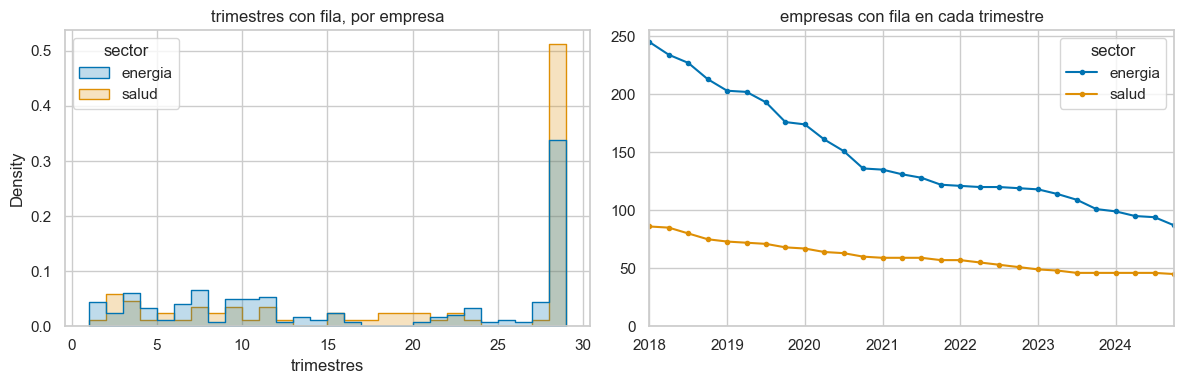

sector,energia,salud
trimestre,,
2018-01-01,245,86
2024-10-01,87,45


In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(
    data=rows_per_company, x="trimestres", hue="sector", palette=PALETTE, bins=range(1, 30),
    stat="density", common_norm=False, element="step", ax=ax1,
)
ax1.set_title("trimestres con fila, por empresa")

active = panel.groupby(["trimestre", "sector"])["cik"].nunique().unstack("sector")
active.index = active.index.to_timestamp()
active.plot(ax=ax2, color=[PALETTE[s] for s in active.columns], marker=".")
ax2.set_title("empresas con fila en cada trimestre")
ax2.set_xlabel("")
ax2.set_ylim(bottom=0)
plt.tight_layout()
plt.show()

for sector in SECTORS:
    summary[f"activas_2024Q4_{sector}"] = int(active[sector].iloc[-1])
active.iloc[[0, -1]]

## 2. Cobertura de conceptos y ratios; empresas con datos completos

**Qué se mira.** Para cada concepto y ratio, el porcentaje de filas con valor, por sector y por trimestre. Después, cuántas empresas tienen cada concepto en **todas** sus filas, y cuántas tienen completo el núcleo que necesita cada objetivo.

**Por qué.** Es la primera pregunta del checklist de la mentora: cuántas empresas tienen datos completos y cómo se tratan los parciales. Un ratio con poca cobertura (por ejemplo `margen_bruto`, que depende de `GrossProfit` o de `CostOfRevenue`, que pocas empresas de energía informan; `docs/decisions.md`, sección 12) sirve poco como variable del modelo. También se mide cuántos `pasivos_totales` faltantes se podrían reconstruir como `activos_totales − patrimonio_neto`, y si esa identidad se cumple donde están los tres.

**Conclusión.** El balance y el flujo de caja están casi completos: `activos_totales`, `activos_corrientes`, `pasivos_corrientes`, `flujo_caja_operativo` y `resultado_neto` tienen valor en más del 98 % de las filas, en los dos sectores y de forma estable en el tiempo (el mapa de calor no muestra trimestres con huecos). Hay tres faltantes importantes:

1. **`pasivos_totales`: 77 %** (75 % en energía, 81 % en salud). Muchas empresas, incluso grandes como HCA y Occidental (sección 3), no informan el tag `Liabilities`: en el balance muestran solo el total de pasivos más patrimonio. Arrastra a `endeudamiento` (76 %). De las 1.343 filas sin pasivos, 1.143 se podrían reconstruir como `activos_totales − patrimonio_neto`, pero donde están los tres valores la identidad se cumple (±1 %) solo en el 79 % de las filas, porque `StockholdersEquity` no incluye las participaciones minoritarias ni algunas acciones preferentes: la reconstrucción sobreestimaría los pasivos en esas empresas.
2. **`ingresos_netos`: 82 %** y **`resultado_operativo`: 85 %**. Faltan en una de cada seis filas y arrastran a los márgenes (67–79 %) y a `fco_ingresos` (79 %). Puede ser por tags de ingresos no contemplados en `shared/concepts.py`; conviene revisarlo con el análisis de cobertura de tags (`TODO.md`).
3. **`ganancia_bruta`: 17 %** (11 % en energía, 34 % en salud), aun con la construcción `ingresos − costo de ventas`. `margen_bruto` queda en 8 % y 30 %.

Empresas con datos completos: solo **18 de 331** tienen los 11 conceptos en todas sus filas; 220 tienen completos `resultado_neto` e `ingresos_netos` (objetivos 1 y 2) y 182 el balance. Exigir filas completas dejaría una muestra mínima.

**Propuesta.** Mantener el panel no balanceado y las filas parciales (`docs/decisions.md`, sección 13). En el modelo, usar algoritmos que toleren faltantes (árboles de gradiente) o imputar por empresa con el último valor disponible. Descartar `margen_bruto` como variable general, o usarlo solo en salud. Evaluar la reconstrucción de `pasivos_totales` con una bandera que indique que es reconstruido, y revisar los tags de ingresos.

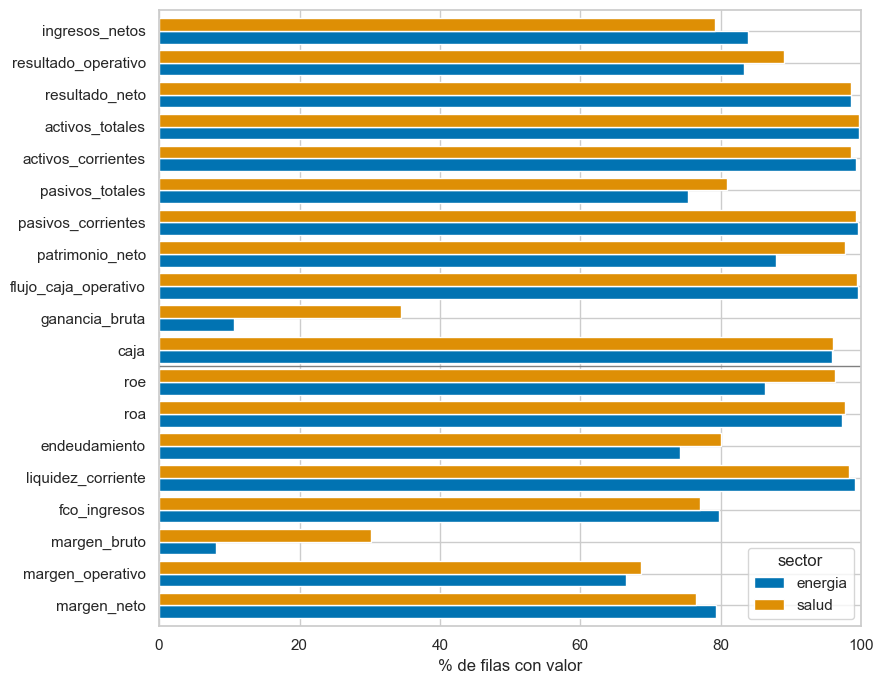

sector,energia,salud,total
ingresos_netos,83.9,79.2,82.5
resultado_operativo,83.3,89.0,85.0
resultado_neto,98.5,98.6,98.5
activos_totales,99.7,99.7,99.7
activos_corrientes,99.2,98.5,99.0
pasivos_totales,75.3,80.9,76.9
pasivos_corrientes,99.6,99.3,99.6
patrimonio_neto,87.8,97.7,90.7
flujo_caja_operativo,99.5,99.4,99.5
ganancia_bruta,10.6,34.4,17.5


In [8]:
ALL_COLUMNS = CONCEPT_COLUMNS + RATIO_COLUMNS
cov = coverage(panel, ALL_COLUMNS, by="sector").T
cov["total"] = coverage(panel, ALL_COLUMNS)
for column in ["ganancia_bruta", "pasivos_totales", "endeudamiento", "margen_bruto"]:
    for sector in SECTORS:
        summary[f"cobertura_{column}_{sector}"] = cov.loc[column, sector]

ax = cov.loc[ALL_COLUMNS[::-1], SECTORS].plot.barh(
    color=[PALETTE[s] for s in SECTORS], figsize=(9, 7), width=0.8
)
ax.axhline(len(RATIO_COLUMNS) - 0.5, color="gray", linewidth=1)  # ratios below, concepts above
ax.set_xlabel("% de filas con valor")
ax.set_xlim(0, 100)
plt.tight_layout()
plt.show()
cov

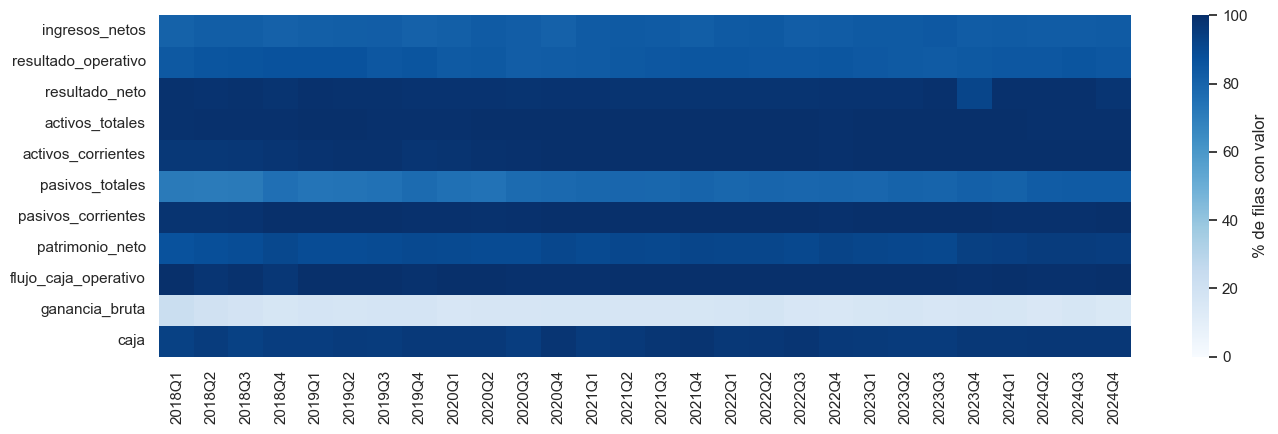

In [9]:
# % of rows with a value, per concept and quarter
by_quarter = panel[CONCEPT_COLUMNS].notna().groupby(panel["trimestre"]).mean() * 100
by_quarter.index = by_quarter.index.astype(str)

fig, ax = plt.subplots(figsize=(14, 4.5))
sns.heatmap(
    by_quarter.T, cmap="Blues", vmin=0, vmax=100, ax=ax,
    cbar_kws={"label": "% de filas con valor"},
)
ax.set_xlabel("")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

In [10]:
# a concept is "complete" for a company if every one of its rows has a value
complete_by_company = panel[CONCEPT_COLUMNS].notna().groupby(panel["cik"]).all()
company_sector = panel.groupby("cik")["sector"].first()
n_complete = complete_by_company.sum(axis=1).rename("conceptos_completos")

CORE = {
    "resultado_neto e ingresos_netos (objetivos 1 y 2)": ["resultado_neto", "ingresos_netos"],
    "balance (activos, pasivos, patrimonio)": [
        "activos_totales", "activos_corrientes", "pasivos_totales",
        "pasivos_corrientes", "patrimonio_neto",
    ],
    "los 11 conceptos": CONCEPT_COLUMNS,
}
core = pd.DataFrame(
    {name: complete_by_company[cols].all(axis=1) for name, cols in CORE.items()}
)
core_by_sector = core.groupby(company_sector).sum().T
core_by_sector["total"] = core_by_sector.sum(axis=1)
summary["empresas_11_conceptos_completos"] = int(core_by_sector.loc["los 11 conceptos", "total"])

# pasivos_totales missing but recoverable as activos - patrimonio
recoverable = (
    panel["pasivos_totales"].isna()
    & panel["activos_totales"].notna()
    & panel["patrimonio_neto"].notna()
)
summary["filas_pasivos_recuperables"] = int(recoverable.sum())
# does the identity hold where the three values exist? (minority interest breaks it)
three = panel[["activos_totales", "pasivos_totales", "patrimonio_neto"]].dropna()
gap = (three["activos_totales"] - three["pasivos_totales"] - three["patrimonio_neto"]).abs()
identity_ok = (gap <= 0.01 * three["activos_totales"].abs()).mean() * 100
summary["pct_identidad_balance_1pct"] = round(identity_ok, 1)

print(f"filas sin pasivos_totales: {panel['pasivos_totales'].isna().sum()}, "
      f"recuperables como activos - patrimonio: {recoverable.sum()}")
print(f"filas con los tres valores: {len(three)}; "
      f"activos = pasivos + patrimonio (±1%) en el {identity_ok:.1f}%")
display(pd.crosstab(company_sector, n_complete))
core_by_sector

filas sin pasivos_totales: 1343, recuperables como activos - patrimonio: 1143
filas con los tres valores: 4113; activos = pasivos + patrimonio (±1%) en el 78.8%


conceptos_completos,2,3,5,6,7,8,9,10,11
sector,,,,,,,,,
energia,1,0,3,9,25,46,95,58,8
salud,0,1,1,2,4,15,24,29,10


sector,energia,salud,total
resultado_neto e ingresos_netos (objetivos 1 y 2),165,55,220
"balance (activos, pasivos, patrimonio)",124,58,182
los 11 conceptos,8,10,18


## 3. Verificación de unidades

**Qué se mira.** Las cifras de 2023 de una empresa conocida por sector, comparadas con su 10-K: HCA Healthcare (salud, el mayor operador de hospitales de EE. UU.) y ConocoPhillips (energía). Se suman los cuatro trimestres de ingresos y resultado neto, porque el panel tiene flujos trimestrales y el 10-K informa el año. Si la empresa no está en el panel, se usa la más grande del sector por activos. Después, la distribución de `log10(activos_totales)` por sector, para ver si hay un grupo de empresas con cifras sospechosamente chicas (informadas en miles).

**Por qué.** Es un punto del checklist de la mentora. Los Financial Statement Data Sets traen los valores en unidades (USD), pero un error de escala en la construcción multiplicaría o dividiría todos los montos por mil; los ratios no lo mostrarían, porque son cocientes.

**Conclusión.** Las cifras están en USD y coinciden con los 10-K. HCA 2023: ingresos 64,97 mil millones, resultado neto 5,24, activos 56,21 y patrimonio −1,77 (HCA tiene patrimonio negativo por recompras de acciones; es el caso de la sección 5). Su 10-K 2023 informa 64.968, 5.242, 56.211 y −1.769 millones de USD: coinciden al millón. ConocoPhillips no está en el panel, así que se usó la mayor de energía por activos, Occidental Petroleum: ingresos 28,26, resultado neto 4,70, activos 74,01 y patrimonio 30,25 mil millones, también en línea con su 10-K 2023 (28.257, 4.696, 74.008 y 30.250 millones). Cifras de los 10-K citadas de memoria: el grupo debería confirmarlas en EDGAR antes del informe.

Ninguna de las dos informa `pasivos_totales`: confirma que el hueco de la sección 2 viene de empresas que no usan el tag `Liabilities`, no de errores de construcción.

La mediana de activos es de unos 400 millones de USD en los dos sectores (10^8,6), sin un segundo grupo alrededor de 10^5 que sugiera cifras en miles. Sí hay una cola de empresas minúsculas: el P1 está en 5.000–20.000 USD de activos (10^3,7 en energía, 10^4,3 en salud), más 46 filas con activos ≤ 0 y 19 sin activos. Son empresas casi sin actividad (*shells*), y son las que producen los ratios extremos de la sección 5.

In [11]:
REFERENCE = {"salud": "860730", "energia": "1163165"}  # HCA Healthcare, ConocoPhillips
MONEY = ["ingresos_netos", "resultado_neto", "activos_totales", "pasivos_totales", "patrimonio_neto"]


def reference_table(cik: str, year: int) -> pd.DataFrame:
    """Quarterly values of `year` in billions of USD, plus the sum of the flows."""
    rows = panel[(panel["cik"] == cik) & (panel["anio"] == year)]
    table = rows.set_index("trimestre")[MONEY] / 1e9
    total = table[["ingresos_netos", "resultado_neto"]].sum()
    table.loc["suma 4 trimestres"] = total
    return table.round(2)


for sector, cik in REFERENCE.items():
    if cik not in set(panel["cik"]):
        largest = panel.loc[panel["sector"] == sector, "activos_totales"].idxmax()
        cik = panel.loc[largest, "cik"]
        print(f"{sector}: la empresa de referencia no está en el panel; se usa la mayor por activos")
    name = panel.loc[panel["cik"] == cik, "nombre"].iloc[-1]
    print(f"\n{sector}: {name} (cik {cik}), 2023, miles de millones de USD")
    display(reference_table(cik, 2023))


salud: HCA HEALTHCARE, INC. (cik 860730), 2023, miles de millones de USD


,ingresos_netos,resultado_neto,activos_totales,pasivos_totales,patrimonio_neto
trimestre,,,,,
2023Q1,15.59,1.36,52.71,NaN,-2.50
2023Q2,15.86,1.19,53.59,NaN,-2.30
2023Q3,16.21,1.08,54.59,NaN,-2.48
2023Q4,17.30,1.61,56.21,NaN,-1.77
suma 4 trimestres,64.97,5.24,NaN,NaN,NaN


energia: la empresa de referencia no está en el panel; se usa la mayor por activos

energia: OCCIDENTAL PETROLEUM CORP /DE/ (cik 797468), 2023, miles de millones de USD


,ingresos_netos,resultado_neto,activos_totales,pasivos_totales,patrimonio_neto
trimestre,,,,,
2023Q1,7.22,1.26,71.60,NaN,29.56
2023Q2,6.70,0.86,71.20,NaN,29.11
2023Q3,7.16,1.38,71.83,NaN,29.31
2023Q4,7.17,1.20,74.01,NaN,30.25
suma 4 trimestres,28.26,4.70,NaN,NaN,NaN


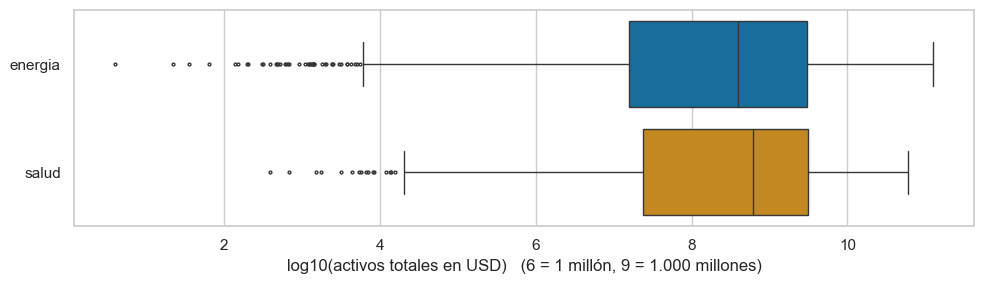

filas con activos_totales <= 0: 46; sin activos_totales: 19


,filas,pct_nan,min,P1,P5,P25,P50,P75,P95,P99,max
sector,,,,,,,,,,,
energia,4128,1.19,0.60,3.67,5.56,7.20,8.60,9.48,10.34,10.66,11.10
salud,1686,0.95,2.59,4.31,5.82,7.38,8.79,9.50,10.25,10.68,10.77


In [12]:
log_assets = panel.assign(log10_activos=log10_positive(panel["activos_totales"]))
fig, ax = plt.subplots(figsize=(10, 3))
sns.boxplot(
    data=log_assets, x="log10_activos", y="sector", hue="sector", palette=PALETTE,
    legend=False, fliersize=2, ax=ax,
)
ax.set_xlabel("log10(activos totales en USD)   (6 = 1 millón, 9 = 1.000 millones)")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

non_positive = panel["activos_totales"] <= 0
print(f"filas con activos_totales <= 0: {non_positive.sum()}; sin activos_totales: {panel['activos_totales'].isna().sum()}")
describe_by_sector(log_assets, "log10_activos").round(2)

## 4. Distribución de conceptos y ratios

**Qué se mira.** Primero los montos: el tamaño de las empresas (ingresos y activos en escala logarítmica) y cuántas filas tienen denominadores casi nulos o negativos (`ingresos_netos ≤ 0` o menores a 1 millón de USD, `activos_totales` menores a 1 millón, `patrimonio_neto ≤ 0`). Después los 8 ratios: percentiles por sector y, para cada uno, el boxplot con todos los valores (eje `symlog`, que es logarítmico hacia los dos lados y lineal cerca de cero) y el histograma entre P5 y P95. Se recorta a P5–P95 y no a P1–P99 porque las colas son tan largas que, con el 1 % de cada lado, el histograma sigue siendo una sola barra.

**Por qué.** Los ratios son cocientes, y un denominador cercano a cero produce valores enormes que no describen a la empresa sino a la división. Antes de fijar umbrales de outliers (sección 5) hay que saber cuántas filas están en esa situación y si los sectores se distribuyen distinto: la guía de la mentora pide justificar si el mismo umbral sirve para los dos.

**Conclusión.** Los ingresos trimestrales tienen dos modas: un grupo de empresas chicas alrededor de 1 millón de USD y el grueso entre 100 millones y 10.000 millones; la mediana de activos ronda los 400 millones en los dos sectores. Los denominadores problemáticos no son raros: el **18,6 % de las filas de energía y el 14,8 % de salud tienen ingresos trimestrales menores a 1 millón de USD** (68 y 20 empresas), el 4,2 % y el 2,4 % tienen ingresos nulos o negativos, y el 7 % tiene activos menores a 1 millón. El **patrimonio es nulo o negativo en el 17 % de las filas de energía (85 empresas) y en el 23 % de salud (39 empresas)**: es frecuente, y concentra el problema del ROE (sección 5).

Las medianas de los ratios son razonables y parecidas entre sectores: ROA trimestral −0,3 % y −0,2 % (más de la mitad de las filas tiene pérdida), endeudamiento 0,47 y 0,57, liquidez corriente 1,13 y 1,46, márgenes cercanos a cero. Pero las colas son enormes: el P1 del margen neto es −76 en energía y −135 en salud, el P99 del endeudamiento es 817 y 89, y los extremos llegan a ±100.000. Hasta el P5–P95 las distribuciones de los dos sectores son similares; difieren en las colas: salud tiene colas negativas más largas en los márgenes y en FCO/ingresos (biotecnológicas que gastan en investigación con ventas mínimas), y energía las tiene en endeudamiento y ROA (empresas casi vacías). Esto importa para la sección 5: un recorte por percentiles cae en puntos distintos en cada sector.

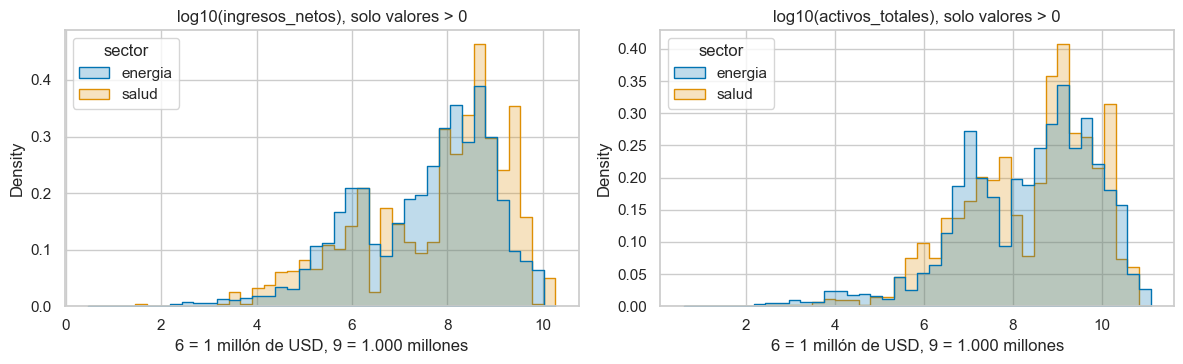

filas       % de filas       empresas      
sector                    energia salud    energia salud  energia salud
ingresos_netos <= 0           174    41        4.2   2.4       23    13
ingresos_netos < 1 M USD      767   250       18.6  14.8       68    20
activos_totales < 1 M USD     304   110        7.4   6.5       30    12
patrimonio_neto <= 0          718   386       17.4  22.9       85    39
resultado_neto == 0             0     1        0.0   0.1        0     1

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, column in zip(axes, ["ingresos_netos", "activos_totales"]):
    data = panel.assign(log10=log10_positive(panel[column]))
    sns.histplot(
        data=data, x="log10", hue="sector", palette=PALETTE, bins=40, stat="density",
        common_norm=False, element="step", ax=ax,
    )
    ax.set_title(f"log10({column}), solo valores > 0")
    ax.set_xlabel("6 = 1 millón de USD, 9 = 1.000 millones")
plt.tight_layout()
plt.show()

conditions = pd.DataFrame({
    "ingresos_netos <= 0": panel["ingresos_netos"] <= 0,
    "ingresos_netos < 1 M USD": panel["ingresos_netos"] < 1e6,
    "activos_totales < 1 M USD": panel["activos_totales"] < 1e6,
    "patrimonio_neto <= 0": panel["patrimonio_neto"] <= 0,
    "resultado_neto == 0": panel["resultado_neto"] == 0,
})
tiny = pd.concat(
    {
        "filas": conditions.groupby(panel["sector"]).sum().T,
        "% de filas": (conditions.groupby(panel["sector"]).mean() * 100).round(1).T,
        "empresas": conditions.groupby(panel["cik"]).any().groupby(company_sector).sum().T,
    },
    axis=1,
)
for sector in SECTORS:
    summary[f"pct_filas_ingresos_menor_1M_{sector}"] = tiny.loc["ingresos_netos < 1 M USD", ("% de filas", sector)]
    summary[f"filas_patrimonio_no_positivo_{sector}"] = int(tiny.loc["patrimonio_neto <= 0", ("filas", sector)])
    summary[f"empresas_patrimonio_no_positivo_{sector}"] = int(tiny.loc["patrimonio_neto <= 0", ("empresas", sector)])
tiny

In [14]:
ratio_stats = pd.concat(
    {r: describe_by_sector(panel, r) for r in RATIO_COLUMNS}, names=["ratio", "sector"]
)
for (ratio, sector), row in ratio_stats.iterrows():
    summary[f"mediana_{ratio}_{sector}"] = round(row["P50"], 3)
ratio_stats.round(3)

filas  pct_nan         min       P1      P5  \
ratio              sector                                                 
roe                energia   4128   13.687     -54.699   -3.365  -0.565   
                   salud     1686    3.677     -71.894   -4.821  -0.684   
roa                energia   4128    2.689   -7688.500  -33.281  -0.670   
                   salud     1686    2.313   -2492.604  -11.170  -1.088   
endeudamiento      energia   4128   25.824       0.002    0.022   0.053   
                   salud     1686   19.988       0.002    0.035   0.070   
liquidez_corriente energia   4128    0.921       0.000    0.000   0.024   
                   salud     1686    1.661       0.000    0.009   0.067   
fco_ingresos       energia   4128   20.252   -5406.156  -20.341  -1.524   
                   salud     1686   22.954   -2684.688  -71.568  -6.886   
margen_bruto       energia   4128   91.860    -178.000   -4.800  -1.260   
                   salud     1686   69.751      -9.417   -3.249  -0.305   
margen_operativo   energia   4128   33.454 -126416.333  -46.643  -4.816   
                   salud     1686   31.435   -8025.229 -134.768 -14.847   
margen_neto        energia   4128   20.688 -143664.333  -76.033  -5.201   
                   salud     1686   23.547  -67052.042 -134.991 -17.709   

                              P25    P50    P75     P95      P99         max  
ratio              sector                                                     
roe                energia -0.038  0.014  0.071   0.543    2.967     342.499  
                   salud   -0.080  0.017  0.060   0.559    3.481      44.384  
roa                energia -0.043 -0.003  0.021   0.089    0.245   11483.544  
                   salud   -0.079 -0.002  0.014   0.046    0.290     382.498  
endeudamiento      energia  0.253  0.470  0.799  10.379  817.480  103962.500  
                   salud    0.348  0.568  0.907   7.518   88.670    8902.041  
liquidez_corriente energia  0.546  1.131  2.286  10.809   40.084     125.705  
                   salud    0.945  1.459  2.844  13.545   29.594     359.403  
fco_ingresos       energia  0.038  0.304  0.582   0.916    2.134     123.520  
                   salud   -0.106  0.053  0.147   0.432    1.970     140.167  
margen_bruto       energia  0.043  0.155  0.343   0.829    1.000       1.327  
                   salud    0.236  0.358  0.617   0.973    1.204       8.853  
margen_operativo   energia -0.342  0.034  0.306   0.596    1.040      30.282  
                   salud   -0.408  0.026  0.100   0.243    0.703      45.359  
margen_neto        energia -0.397 -0.002  0.222   0.581    2.822     256.719  
                   salud   -0.329  0.010  0.073   0.204    1.809     389.842

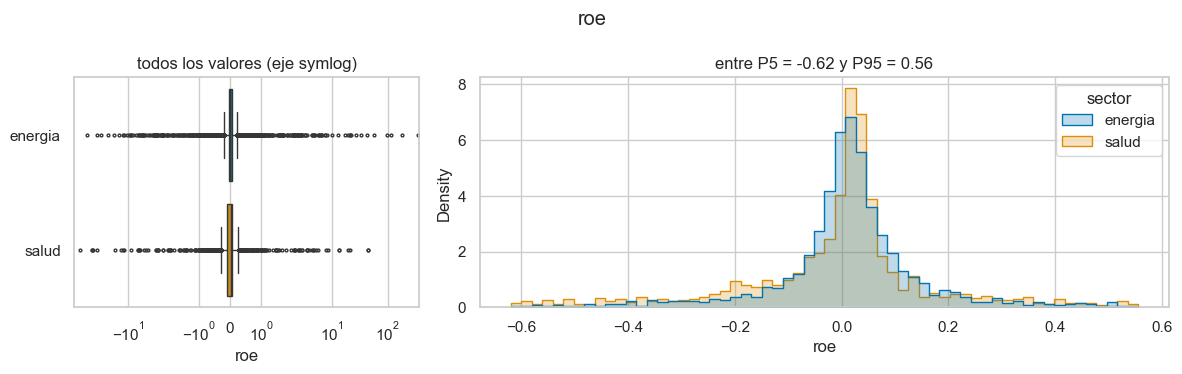

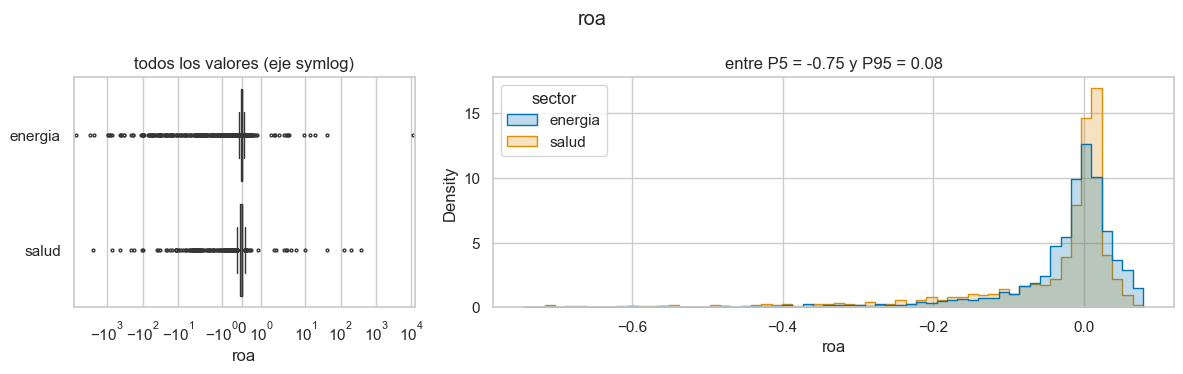

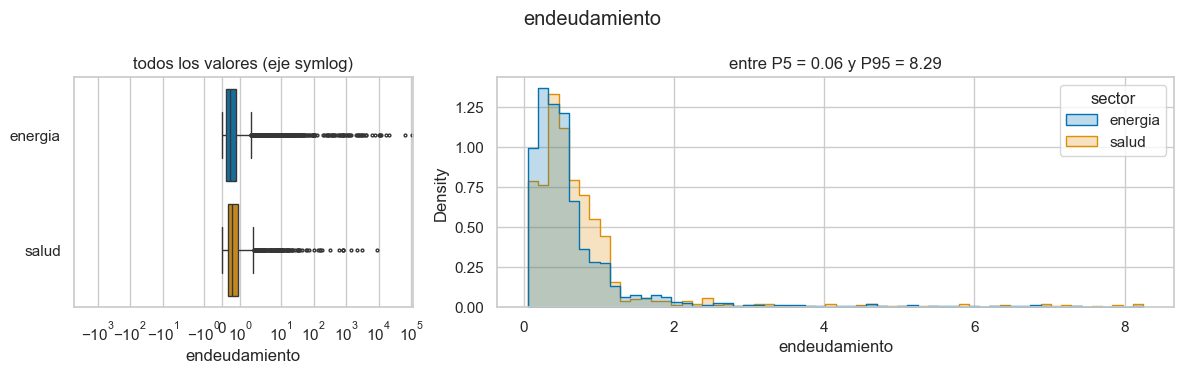

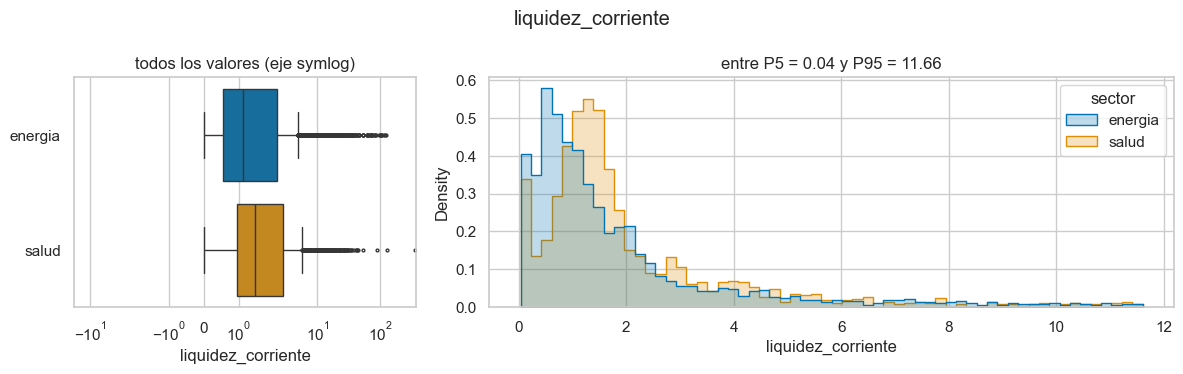

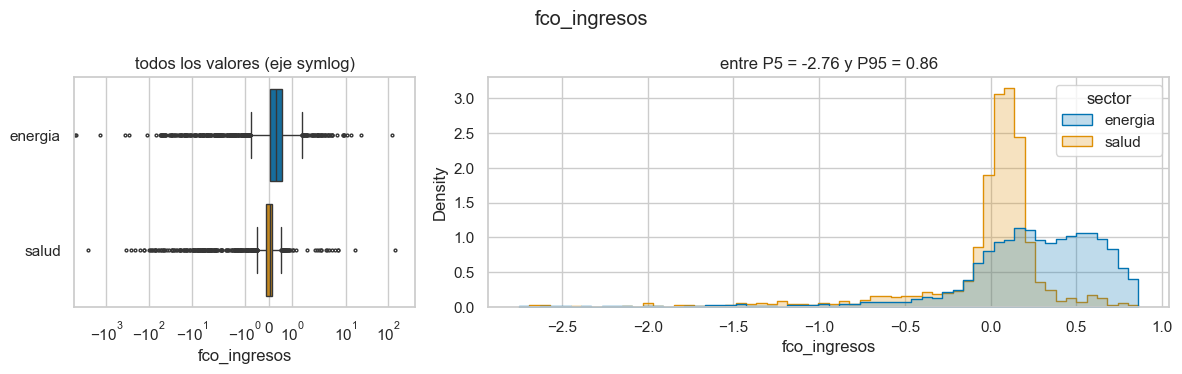

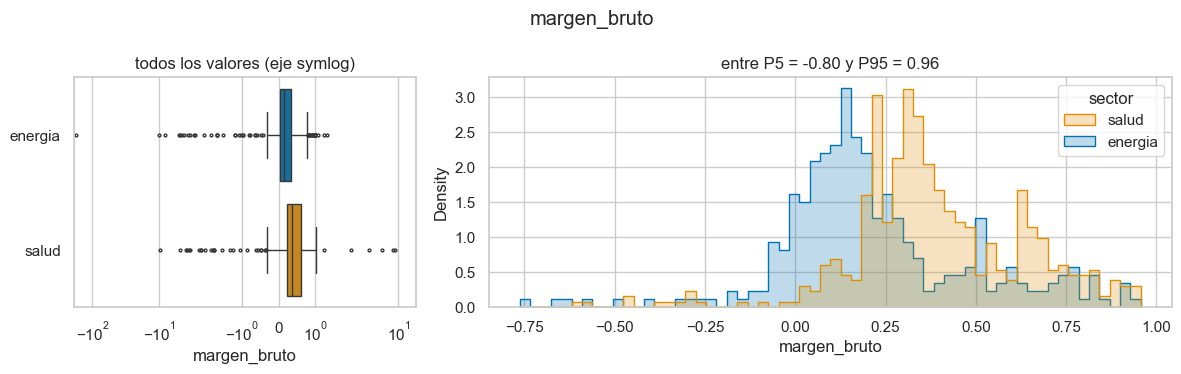

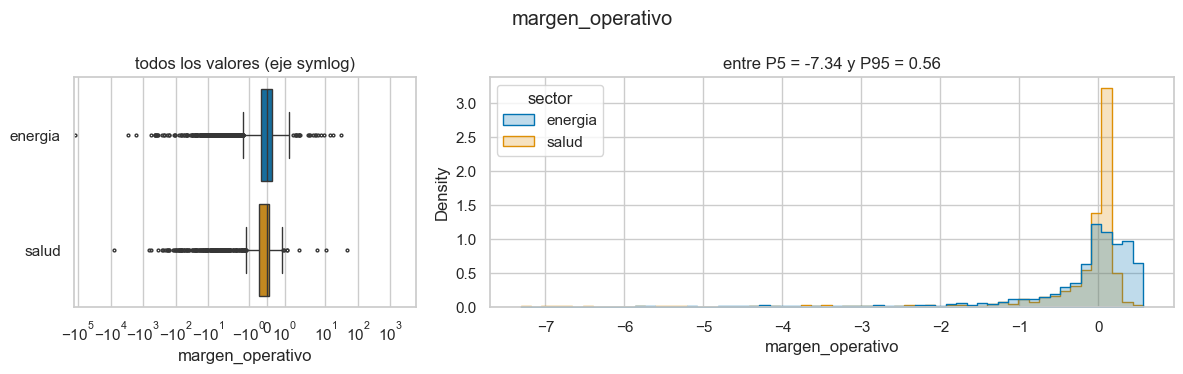

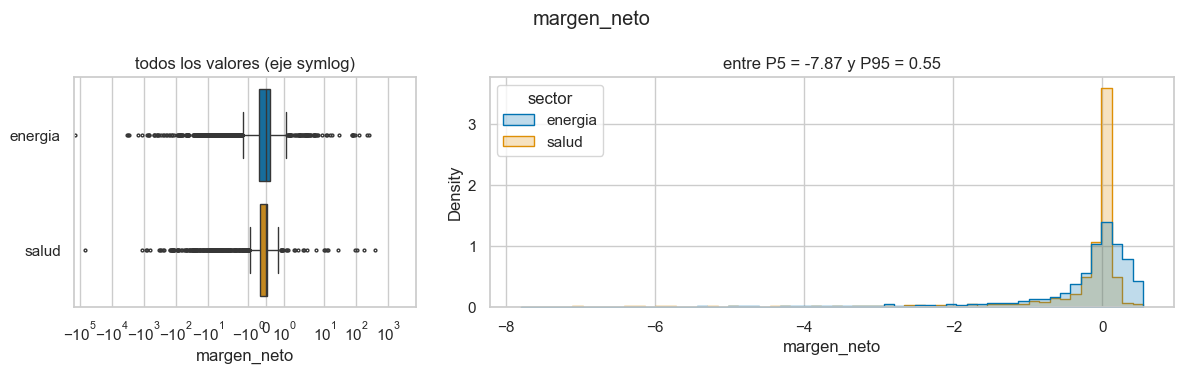

In [15]:
for ratio in RATIO_COLUMNS:
    plot_ratio_by_sector(panel, ratio)

## 5. Outliers y ROE con patrimonio negativo

**Qué se mira.** Cuántas filas y empresas quedan marcadas como outliers con umbrales fijos: los de la guía de la mentora (sección 5) para los márgenes, fuera de (−500 %, 200 %), y para el endeudamiento, mayor a 5; y umbrales propuestos con la misma lógica para los demás ratios (valores poco interpretables para una empresa que opera; son una propuesta con criterio propio, no salen de una fuente). Se mide por sector, se caracteriza a las filas marcadas (tamaño de la empresa) y se compara con la alternativa de recortar a los percentiles 1 y 99 de cada sector (*winsorizar*). Al final, el caso del ROE con patrimonio negativo: cuando el patrimonio es negativo, el signo del ROE se invierte y el ratio engaña (una empresa con ganancia y patrimonio negativo tiene ROE negativo, y una con pérdida y patrimonio negativo tiene ROE positivo).

**Por qué.** Es el pendiente de `TODO.md` y una pregunta del checklist: qué umbral se usa en cada ratio y si se aplica igual en los dos sectores. Un ratio de −100.000 no es información sobre la empresa, y en un modelo lineal o en una media domina a todas las demás filas.

**Conclusión.** Con los umbrales fijos, los ratios más afectados son los márgenes: quedan fuera el 10,4 % de las filas con margen neto en salud y el 6,4 % en energía, y el 9,9 % y 5,3 % del margen operativo. Siguen endeudamiento (6–7 %), ROA (4,5–5,8 %) y FCO/ingresos (2,8 % y 7,2 %); ROE y liquidez corriente, menos del 2 %. Las filas marcadas son **sobre todo de empresas minúsculas**: su mediana de ingresos es 0,1 millones de USD contra 109 millones en las demás, y la de activos 1,8 millones contra 732. El **80 % de las filas marcadas (557 de 698)** tiene ingresos o activos menores a 1 millón (10^6), y los dos gráficos de dispersión muestran el mismo patrón. Buena parte de los extremos viene de denominadores casi nulos, pero no todos: también hay pérdidas muy grandes en empresas grandes (14 filas con margen neto fuera del umbral tienen más de 100 millones de USD de ingresos, por ejemplo Concho Resources en 2020Q1). Estos análisis no permiten descartar errores de carga.

Sectores: en endeudamiento, ROA y ROE los porcentajes son parecidos, pero en los márgenes salud marca casi el doble, porque tiene más empresas con ingresos ínfimos (biotecnológicas sin producto). Los percentiles 1 y 99 difieren mucho entre sectores (P99 del endeudamiento: 817 en energía y 89 en salud; P1 del margen operativo: −47 y −135), así que un recorte por percentiles por sector trata distinto a las mismas situaciones. Además, winsorizar a P1–P99 no alcanza: el desvío del margen neto baja de 2.349 a 12,6, pero la media sigue en −2,4 cuando la mediana es 0,004.

ROE: el patrimonio es negativo en **1.100 filas de 123 empresas**, y en todas ellas el signo del ROE engaña. En 194 filas (87 de energía y 107 de salud) la empresa gana y el ROE es negativo: HCA gana 1.400 millones por trimestre con ROA del 2,4–2,8 % y ROE de −0,6 a −1,0. En 906 filas (627 y 279) la empresa pierde y el ROE es positivo. El gráfico de dispersión muestra los dos cuadrantes del lado izquierdo.

Outliers y quiebra: las filas marcadas no son ruido para el objetivo 3. Entre las filas cuyo año siguiente está dentro del panel (hasta 2023Q4), **el 5,8 % de las que tienen algún ratio fuera de umbral quiebra dentro del año, contra el 2,8 % del resto**; con patrimonio negativo, 6,8 % contra 2,3 %. Los outliers de empresas no minúsculas (132 filas: pérdidas enormes de empresas grandes, como Concho en 2020Q1) quiebran 6 veces más que el resto (16,7 %), y son las primeras que borraría un filtro automático. Las empresas minúsculas, en cambio, quiebran menos (1,5 % contra 3,7 %): no entran en Chapter 11, dejan de presentar (sección 9). Son 50 quiebras en total, así que los porcentajes de los grupos chicos son poco precisos. Sensibilidad de los 4 umbrales propuestos: solo con los de la guía quedan marcadas 576 filas (9,9 %); con los propuestos a la mitad, 897 (15,4 %); al doble, 625 (10,7 %). Mueven el total en 2–3 puntos y no cambian la conclusión.

**Propuesta** (decisión pendiente del grupo, a registrar en `docs/decisions.md`, sección 13):
1. Usar los umbrales fijos de la guía para los márgenes y el endeudamiento, y los propuestos acá para el resto, **iguales en los dos sectores**: los extremos tienen la misma causa en ambos. **Marcar y no borrar**: una bandera `outlier` por fila, porque las empresas minúsculas y con pérdidas enormes son justamente candidatas a quebrar y borrarlas sesgaría el objetivo 3. Para los modelos sensibles a la escala, recortar los ratios a los umbrales (o a P5–P95) en el momento de entrenar.
2. Agregar una bandera `empresa_minuscula` (ingresos trimestrales o activos menores a 1 millón de USD), que resume la causa.
3. `roe` vacío cuando el patrimonio es ≤ 0, más una bandera `patrimonio_negativo`, y usar el ROA como medida principal de rentabilidad.

filas con algún ratio fuera de umbral: 698 (12.0%), en 142 empresas


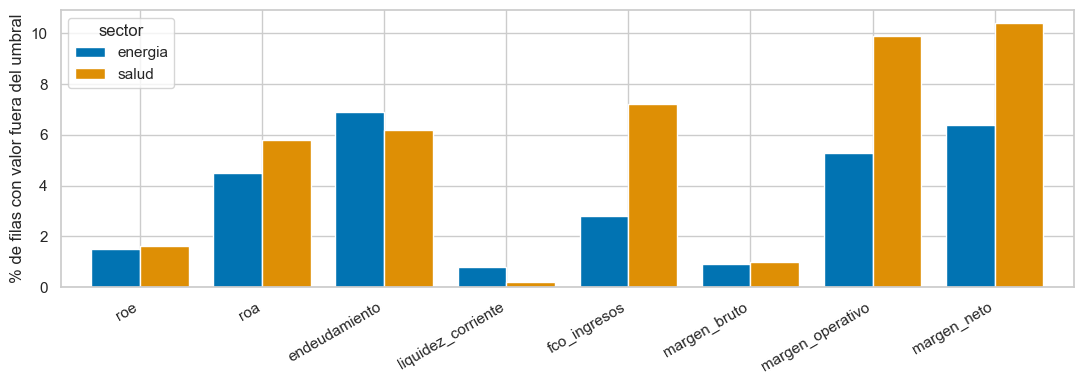

filas       % de filas con valor       empresas      
sector             energia salud              energia salud  energia salud
margen_bruto             3     5                  0.9   1.0        2     4
margen_operativo       146   115                  5.3   9.9       54    16
margen_neto            210   134                  6.4  10.4       74    18
endeudamiento          210    84                  6.9   6.2       25    11
roa                    180    96                  4.5   5.8       38    17
roe                     52    26                  1.5   1.6       36    19
liquidez_corriente      33     4                  0.8   0.2        8     2
fco_ingresos            93    94                  2.8   7.2       23    13

In [16]:
THRESHOLDS = {
    # guía de la mentora, sección 5: márgenes fuera de (-500 %, 200 %) y endeudamiento > 5
    "margen_bruto": (-5, 2),
    "margen_operativo": (-5, 2),
    "margen_neto": (-5, 2),
    "endeudamiento": (None, 5),
    # our proposal for the other ratios (no source): hard-to-interpret values for an operating company
    "roa": (-1, 1),
    "roe": (-5, 5),
    "liquidez_corriente": (None, 50),
    "fco_ingresos": (-5, 5),
}
flags = flag_outliers(panel, THRESHOLDS)
with_value = panel[list(THRESHOLDS)].notna()
out_rows = flags.groupby(panel["sector"]).sum().T
out_pct = (
    flags.groupby(panel["sector"]).sum() / with_value.groupby(panel["sector"]).sum() * 100
).round(1).T
out_companies = flags.groupby(panel["cik"]).any().groupby(company_sector).sum().T
outliers = pd.concat(
    {"filas": out_rows, "% de filas con valor": out_pct, "empresas": out_companies}, axis=1
)
any_flag = flags.any(axis=1)
summary["filas_con_algun_outlier"] = int(any_flag.sum())
summary["empresas_con_algun_outlier"] = panel.loc[any_flag, "cik"].nunique()
for ratio in ["margen_neto", "endeudamiento", "roe"]:
    for sector in SECTORS:
        summary[f"pct_outliers_{ratio}_{sector}"] = out_pct.loc[ratio, sector]
print(f"filas con algún ratio fuera de umbral: {any_flag.sum()} ({any_flag.mean() * 100:.1f}%), "
      f"en {panel.loc[any_flag, 'cik'].nunique()} empresas")

ax = out_pct.loc[RATIO_COLUMNS, SECTORS].plot.bar(color=[PALETTE[s] for s in SECTORS], width=0.8)
ax.set_ylabel("% de filas con valor fuera del umbral")
ax.set_xlabel("")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()
outliers

,"ingresos_netos (mediana, M USD)","activos_totales (mediana, M USD)"
sin outlier,109.1,731.8
con algún outlier,0.1,1.8


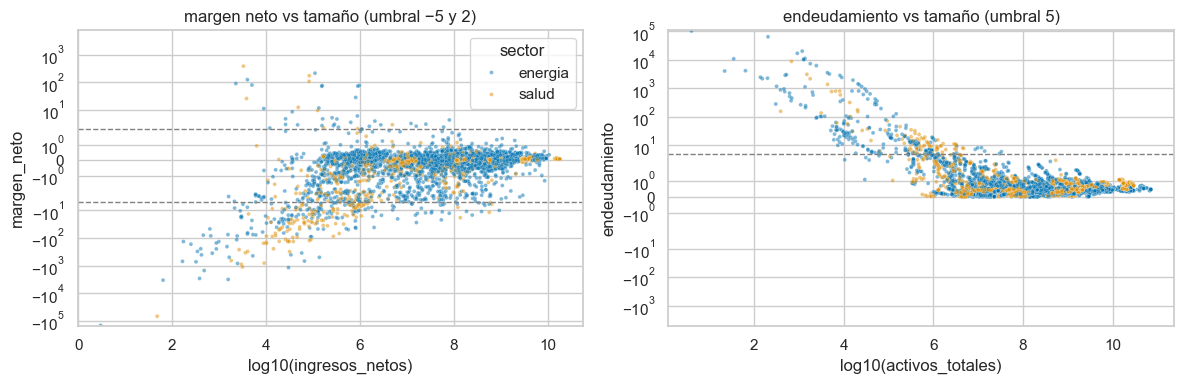

In [17]:
# where are the outliers? size of the company in flagged vs non-flagged rows
size = panel[["ingresos_netos", "activos_totales"]].groupby(any_flag).median().rename(
    index={False: "sin outlier", True: "con algún outlier"}
)
display((size / 1e6).round(1).rename(columns=lambda c: f"{c} (mediana, M USD)"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.scatterplot(
    data=panel.assign(x=log10_positive(panel["ingresos_netos"])), x="x", y="margen_neto",
    hue="sector", palette=PALETTE, s=8, alpha=0.5, ax=axes[0],
)
axes[0].set_yscale("symlog")
for y in THRESHOLDS["margen_neto"]:
    axes[0].axhline(y, color="gray", linestyle="--", linewidth=1)
axes[0].set_xlabel("log10(ingresos_netos)")
axes[0].set_title("margen neto vs tamaño (umbral −5 y 2)")

sns.scatterplot(
    data=panel.assign(x=log10_positive(panel["activos_totales"])), x="x", y="endeudamiento",
    hue="sector", palette=PALETTE, s=8, alpha=0.5, ax=axes[1], legend=False,
)
axes[1].set_yscale("symlog")
axes[1].axhline(THRESHOLDS["endeudamiento"][1], color="gray", linestyle="--", linewidth=1)
axes[1].set_xlabel("log10(activos_totales)")
axes[1].set_title("endeudamiento vs tamaño (umbral 5)")
plt.tight_layout()
plt.show()

In [18]:
# alternative: winsorize at P1 and P99 of each sector
def winsorize_by_sector(df: pd.DataFrame, columns: list, lower=0.01, upper=0.99) -> pd.DataFrame:
    """Clip each column to its percentiles within each sector."""
    return df.groupby("sector")[columns].transform(
        lambda s: s.clip(s.quantile(lower), s.quantile(upper))
    )


winsorized = winsorize_by_sector(panel, RATIO_COLUMNS)
moments = pd.concat(
    {
        "original": panel[RATIO_COLUMNS].agg(["mean", "std"]).T,
        "winsorizado P1-P99 por sector": winsorized.agg(["mean", "std"]).T,
        "mediana": panel[RATIO_COLUMNS].median().rename("P50").to_frame(),
    },
    axis=1,
)
display(moments.round(3))

# do P1 and P99 differ between sectors? (if so, a single threshold treats them differently)
panel.groupby("sector")[RATIO_COLUMNS].quantile([0.01, 0.99]).round(2)

original           winsorizado P1-P99 por sector          \
                       mean       std                          mean     std   
roe                   0.124     6.354                        -0.004   0.673   
roa                  -2.658   196.376                        -0.512   3.392   
endeudamiento        78.751  1936.099                        10.262  77.737   
liquidez_corriente    3.214     9.246                         2.880   5.503   
fco_ingresos         -4.129   118.420                        -0.612   5.446   
margen_bruto          0.018     6.208                         0.217   0.736   
margen_operativo    -39.024  2028.404                        -1.995  10.761   
margen_neto         -52.838  2348.610                        -2.392  12.616   

                   mediana  
                       P50  
roe                  0.016  
roa                 -0.002  
endeudamiento        0.491  
liquidez_corriente   1.249  
fco_ingresos         0.173  
margen_bruto         0.301  
margen_operativo     0.032  
margen_neto          0.004

roe    roa  endeudamiento  liquidez_corriente  fco_ingresos  \
sector                                                                       
energia 0.01 -3.36 -33.28           0.02                0.00        -20.34   
        0.99  2.97   0.24         817.48               40.08          2.13   
salud   0.01 -4.82 -11.17           0.04                0.01        -71.57   
        0.99  3.48   0.29          88.67               29.59          1.97   

              margen_bruto  margen_operativo  margen_neto  
sector                                                     
energia 0.01         -4.80            -46.64       -76.03  
        0.99          1.00              1.04         2.82  
salud   0.01         -3.25           -134.77      -134.99  
        0.99          1.20              0.70         1.81

patrimonio_neto         cero  negativo  positivo
sector  resultado_neto                          
energia negativo           3       627      1374
        positivo           0        87      1475
salud   negativo           0       279       569
        positivo           0       107       669

filas con ROE de signo engañoso (patrimonio < 0): 1100, en 123 empresas


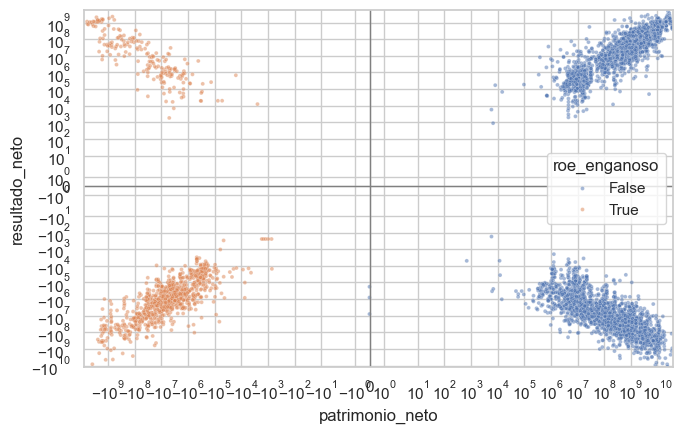

,trimestre,resultado_neto,patrimonio_neto,roe,roa
5213,2024Q1,1.591000e+09,-1.615000e+09,-0.985139,0.027931
5214,2024Q2,1.461000e+09,-1.600000e+09,-0.913125,0.025462
5215,2024Q3,1.270000e+09,-2.182000e+09,-0.582035,0.021359
5216,2024Q4,1.438000e+09,-2.499000e+09,-0.575430,0.024163


In [19]:
# ROE with negative equity: the sign of the ratio is reversed
both = panel[["resultado_neto", "patrimonio_neto"]].notna().all(axis=1)
sign = np.sign(panel.loc[both, ["resultado_neto", "patrimonio_neto"]]).replace(
    {-1: "negativo", 0: "cero", 1: "positivo"}
)
display(pd.crosstab(
    [panel.loc[both, "sector"], sign["resultado_neto"]], sign["patrimonio_neto"],
    rownames=["sector", "resultado_neto"], colnames=["patrimonio_neto"],
))

misleading = both & (panel["patrimonio_neto"] < 0) & (panel["resultado_neto"] != 0)
summary["filas_roe_signo_enganoso"] = int(misleading.sum())
summary["empresas_roe_signo_enganoso"] = panel.loc[misleading, "cik"].nunique()
print(f"filas con ROE de signo engañoso (patrimonio < 0): {misleading.sum()}, "
      f"en {panel.loc[misleading, 'cik'].nunique()} empresas")

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.scatterplot(
    data=panel.assign(roe_enganoso=misleading), x="patrimonio_neto", y="resultado_neto",
    hue="roe_enganoso", s=8, alpha=0.5, ax=ax,
)
ax.set_xscale("symlog")
ax.set_yscale("symlog")
ax.axvline(0, color="gray", linewidth=1)
ax.axhline(0, color="gray", linewidth=1)
plt.tight_layout()
plt.show()

# HCA: profit every quarter, negative equity, negative ROE
panel.loc[panel["cik"] == "860730", ["trimestre", "resultado_neto", "patrimonio_neto", "roe", "roa"]].tail(4)

In [20]:
# are flagged rows informative for bankruptcy? rate of bankruptcy within 1 year, per group
HORIZON = 4  # quarters
observable = panel["trimestre"] + HORIZON <= END  # rows whose next year is inside the panel
bankrupt_1y = bankruptcy_within(panel, HORIZON)
tiny_company = (panel["ingresos_netos"] < 1e6) | (panel["activos_totales"] < 1e6)
negative_equity = panel["patrimonio_neto"] < 0
GROUPS = {
    "algún ratio fuera de umbral": any_flag,
    "outlier en empresa minúscula": any_flag & tiny_company,
    "outlier en empresa no minúscula": any_flag & ~tiny_company,
    "empresa minúscula (ingresos o activos < 1 M USD)": tiny_company,
    "patrimonio negativo": negative_equity,
    "patrimonio negativo con pérdida": negative_equity & (panel["resultado_neto"] < 0),
    "patrimonio negativo con ganancia": negative_equity & (panel["resultado_neto"] > 0),
}
rows = []
for name, mask in GROUPS.items():
    inside, outside = mask & observable, ~mask & observable
    rows.append({
        "grupo": name,
        "filas": int(inside.sum()),
        "quiebra a 1 año (%)": bankrupt_1y[inside].mean() * 100,
        "resto del panel (%)": bankrupt_1y[outside].mean() * 100,
    })
bankruptcy_by_group = pd.DataFrame(rows).set_index("grupo")
bankruptcy_by_group["veces"] = (
    bankruptcy_by_group["quiebra a 1 año (%)"] / bankruptcy_by_group["resto del panel (%)"]
)
print(f"filas con el año siguiente observable (hasta {END - HORIZON}): {observable.sum()}, "
      f"empresas que quiebran dentro de ese año: {panel.loc[observable & bankrupt_1y, 'cik'].nunique()}")
display(bankruptcy_by_group.round(1))
summary["pct_quiebra_1a_outlier"] = round(bankruptcy_by_group.loc["algún ratio fuera de umbral", "quiebra a 1 año (%)"], 1)
summary["pct_quiebra_1a_sin_outlier"] = round(bankruptcy_by_group.loc["algún ratio fuera de umbral", "resto del panel (%)"], 1)
summary["pct_quiebra_1a_patrimonio_negativo"] = round(bankruptcy_by_group.loc["patrimonio negativo", "quiebra a 1 año (%)"], 1)

# sensitivity: rows flagged when the 4 proposed thresholds are halved or doubled
PROPOSED = ["roa", "roe", "liquidez_corriente", "fco_ingresos"]
sensitivity = {}
for label, factor in [("solo guía (sin los 4 propuestos)", None), ("propuestos × 0,5", 0.5),
                      ("propuestos × 1", 1), ("propuestos × 2", 2)]:
    thresholds = {r: b for r, b in THRESHOLDS.items() if r not in PROPOSED}
    if factor is not None:
        thresholds.update({
            r: tuple(None if b is None else b * factor for b in THRESHOLDS[r]) for r in PROPOSED
        })
    flagged = flag_outliers(panel, thresholds).any(axis=1)
    sensitivity[label] = {
        "filas": int(flagged.sum()), "% de filas": flagged.mean() * 100,
        "empresas": panel.loc[flagged, "cik"].nunique(),
    }
pd.DataFrame(sensitivity).T.round(1)


filas con el año siguiente observable (hasta 2023Q4): 5256, empresas que quiebran dentro de ese año: 50


,filas,quiebra a 1 año (%),resto del panel (%),veces
grupo,,,,
algún ratio fuera de umbral,657,5.8,2.8,2.0
outlier en empresa minúscula,525,3.0,3.2,0.9
outlier en empresa no minúscula,132,16.7,2.9,5.8
empresa minúscula (ingresos o activos < 1 M USD),1072,1.5,3.7,0.4
patrimonio negativo,1022,6.8,2.3,2.9
patrimonio negativo con pérdida,838,7.4,2.4,3.1
patrimonio negativo con ganancia,183,4.4,3.2,1.4


,filas,% de filas,empresas
solo guía (sin los 4 propuestos),576.0,9.9,108.0
"propuestos × 0,5",897.0,15.4,172.0
propuestos × 1,698.0,12.0,142.0
propuestos × 2,625.0,10.7,120.0


## 6. Evolución temporal y estacionalidad

**Qué se mira.** La mediana por trimestre y sector del ROA, el margen neto y los ingresos, y después el ROA según el trimestre del año (`q`), para ver si el cuarto trimestre es sistemáticamente distinto.

**Por qué.** Los ratios de rentabilidad del panel son trimestrales, sin anualizar (`docs/decisions.md`, sección 10), así que conservan la estacionalidad y los shocks: la caída del petróleo y la pandemia en 2020 deberían verse en energía. El cuarto trimestre se calcula como el año menos los nueve meses acumulados (sección 9 de `decisions.md`), y es el trimestre donde las empresas suelen registrar ajustes anuales (deterioros de activos, impuestos), así que puede tener una distribución distinta. Si es así, el modelo necesita una variable con el trimestre del año.

**Conclusión.** El shock de 2020 es enorme en energía: en 2020Q2 la mediana del margen neto cae a −0,97 (la empresa típica perdió casi todo lo que vendió, por los deterioros de activos con el petróleo en mínimos) y el **91 % de las empresas de energía tuvo pérdida**, contra el 45 % de salud. Energía se recupera en 2021 y tiene su pico en 2022, con la suba del petróleo tras la invasión de Ucrania (ROA mediano trimestral del 4 %). Salud es estable: ROA mediano alrededor de cero y entre 42 % y 63 % de empresas con pérdida en cada trimestre. La mediana de ingresos de salud se cuadruplica entre 2018 y 2024, pero es en gran parte composición: las empresas que salen del panel son las chicas (secciones 1 y 9), así que la mediana sube sin que las empresas crezcan.

Estacionalidad: en mediana, el cuarto trimestre no es distinto a los demás en ROA ni en margen neto, y el boxplot tampoco muestra diferencias; sí es mayor la mediana de ingresos del Q4 en salud (153 millones contra 115–118). El efecto de los ajustes anuales se ve, en todo caso, en las colas y no en el centro.

**Propuesta.** El año (o una variable del shock de 2020) importa más que el trimestre del año; igual conviene incluir `q` como variable, porque es gratis. Para el objetivo 2, comparar con el mismo trimestre del año anterior evita la estacionalidad que pueda quedar.

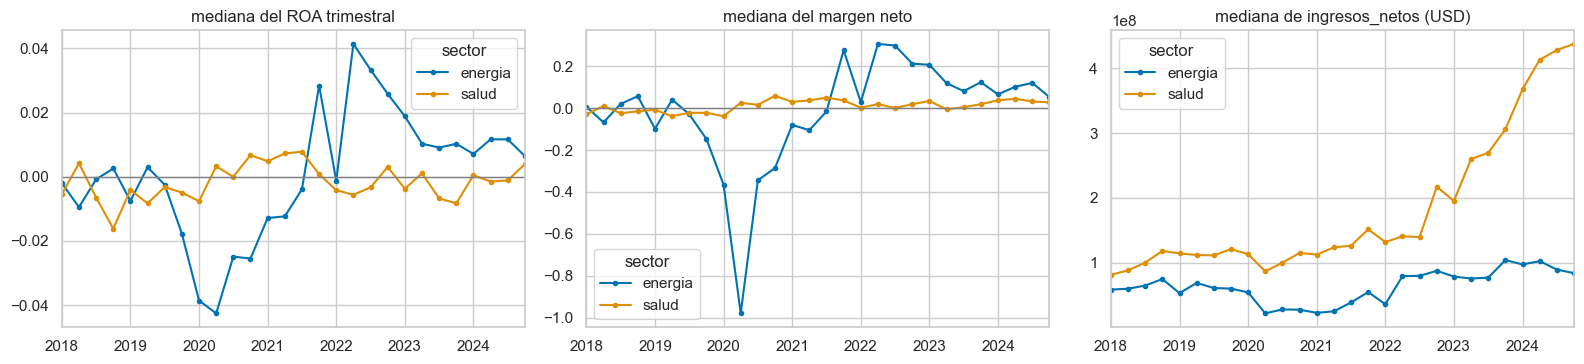

sector,energia,salud
trimestre,,
2019Q4,73.3,57.4
2020Q1,70.1,62.7
2020Q2,91.3,45.3
2020Q3,83.4,49.2
2020Q4,77.2,43.3
2021Q1,65.9,42.4
2021Q2,64.9,42.4


In [21]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
plot_over_time(panel, "roa", ax=axes[0], title="mediana del ROA trimestral")
plot_over_time(panel, "margen_neto", ax=axes[1], title="mediana del margen neto")
plot_over_time(panel, "ingresos_netos", ax=axes[2], title="mediana de ingresos_netos (USD)")
for ax in axes[:2]:
    ax.axhline(0, color="gray", linewidth=1)
plt.tight_layout()
plt.show()

loss_share = (panel["resultado_neto"] < 0).groupby([panel["trimestre"], panel["sector"]]).mean().unstack("sector") * 100
for sector in SECTORS:
    summary[f"pct_perdida_2020Q2_{sector}"] = round(loss_share.loc[pd.Period("2020Q2"), sector], 1)
loss_share.loc["2019Q4":"2021Q2"].round(1)

roa                         margen_neto                          \
q             1       2       3       4           1       2       3       4   
sector                                                                        
energia -0.0033 -0.0044 -0.0005 -0.0023     -0.0189 -0.0136  0.0221  0.0250   
salud   -0.0035 -0.0009 -0.0023 -0.0011     -0.0063  0.0169  0.0143  0.0161   

        ingresos_netos                                         
q                    1            2            3            4  
sector                                                         
energia     56100000.0   50532500.0   55899000.0   61971000.0  
salud      114409500.0  117139500.0  117608000.0  153037000.0

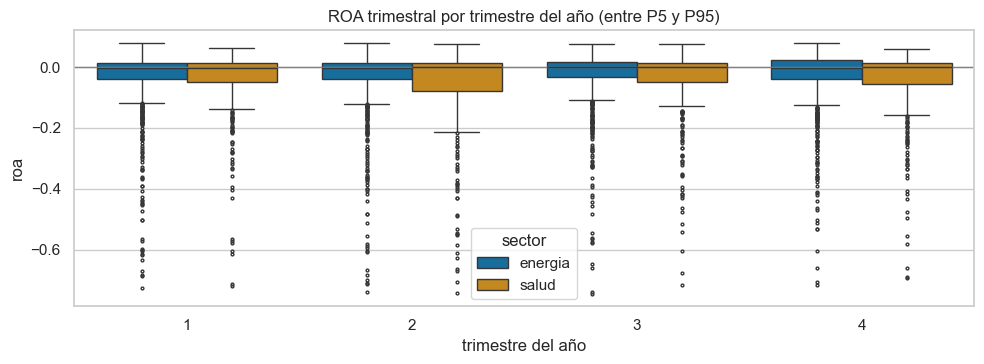

In [22]:
season = panel.groupby(["sector", "q"])[["roa", "margen_neto", "ingresos_netos"]].median()
display(season.unstack("q").round(4))
for sector in SECTORS:
    summary[f"mediana_roa_q4_{sector}"] = round(season.loc[(sector, 4), "roa"], 4)
    summary[f"mediana_roa_q1a3_{sector}"] = round(
        panel.loc[(panel["sector"] == sector) & (panel["q"] < 4), "roa"].median(), 4
    )

lo, hi = panel["roa"].quantile([0.05, 0.95])
fig, ax = plt.subplots(figsize=(10, 3.8))
sns.boxplot(
    data=panel[panel["roa"].between(lo, hi)], x="q", y="roa", hue="sector", palette=PALETTE,
    fliersize=2, ax=ax,
)
ax.axhline(0, color="gray", linewidth=1)
ax.set_title("ROA trimestral por trimestre del año (entre P5 y P95)")
ax.set_xlabel("trimestre del año")
plt.tight_layout()
plt.show()

## 7. Objetivos 1 y 2: ganancia o pérdida, y crecimiento

**Qué se mira.** Para el objetivo 1, la etiqueta es `resultado_neto > 0`: su tasa base por sector y por trimestre, y cuánto persiste de un trimestre al siguiente (matriz de transición entre t−1 y t). Para el objetivo 2, el crecimiento de los ingresos respecto del trimestre anterior (t−1, *QoQ*) y del mismo trimestre del año anterior (t−4, *YoY*): cuántas filas tienen ese rezago disponible, cuántas se pueden etiquetar (hace falta un valor anterior positivo) y la tasa base de "crece". El rezago se busca por empresa y trimestre exacto: si falta el trimestre anterior, la fila queda sin rezago (no se usa la fila anterior disponible).

**Por qué.** La tasa base dice qué tan desbalanceado es cada problema y cuál es el piso de cualquier modelo (predecir siempre la clase mayoritaria). La persistencia del signo dice cuánto explica el pasado inmediato. Y el rumbo no define "período anterior": comparar QoQ y YoY muestra la diferencia y ayuda a elegir.

**Conclusión.** *Objetivo 1.* La etiqueta está balanceada: tienen ganancia el 46 % de las filas de energía y el 47 % de salud (85 filas no tienen `resultado_neto`). Pero la proporción no es estable: en energía va del 7 % en 2020Q2 al 72 % en 2022–2023, mientras que salud oscila entre 37 % y 59 %. El signo es muy persistente: en energía, el 75 % de las empresas que ganaron en t−1 ganan en t y el 79 % de las que perdieron siguen perdiendo; en salud, 83 % y 85 %. Es decir, "repetir el signo del trimestre anterior" acierta alrededor del 77 % en energía y del 84 % en salud: ese es el piso que cualquier modelo tiene que superar, y el trimestre anterior está disponible en el 93 % de las filas.

*Objetivo 2.* Con ingresos, se puede etiquetar el 78 % (energía) y el 74 % (salud) de las filas contra el trimestre anterior, y el 65 % y 62 % contra el año anterior (YoY pierde el primer año del panel y es más sensible a los huecos). La tasa base de "crece" es 50 % y 57 % QoQ, y 47 % y 64 % YoY: en salud, dos de cada tres filas crecen interanualmente, en parte por composición (sobreviven las que crecen). La distribución de la tasa QoQ está centrada en cero y es simétrica; salud está mucho más concentrada (ingresos estables de hospitales y servicios) y energía mucho más dispersa (sigue al precio del petróleo). El porcentaje que crece QoQ oscila trimestre a trimestre; el YoY es más suave en salud, pero en energía sigue el ciclo del petróleo (más del 80 % en 2021–2022, menos del 30 % en 2023). Con el resultado neto, "crece" es prácticamente 50/50 en todos los cortes: es una etiqueta mucho más ruidosa.

**Propuesta.** Definir el objetivo 2 como crecimiento de los **ingresos respecto del mismo trimestre del año anterior** (YoY): evita la estacionalidad y es la comparación habitual en finanzas, a costa de etiquetar el 62–65 % de las filas. Confirmarlo con el grupo y la mentora.

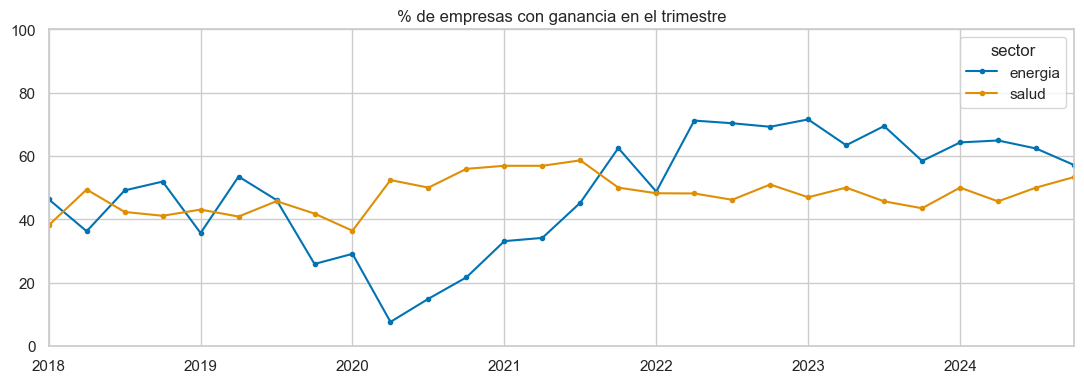

tasa base de ganancia: {'energia': 46.2, 'salud': 47.3}; filas sin etiqueta: 85
transición t-1 -> t (% por fila):


t                 ganancia  pérdida
sector  t-1                        
energia ganancia      74.7     25.3
        pérdida       21.1     78.9
salud   ganancia      83.3     16.7
        pérdida       15.5     84.5

In [23]:
has_label = panel["resultado_neto"].notna()
profit = (panel["resultado_neto"] > 0).astype(float).where(has_label)  # NaN if no label
summary["filas_sin_resultado_neto"] = int((~has_label).sum())
base_rate = profit.groupby(panel["sector"]).mean() * 100
for sector in SECTORS:
    summary[f"pct_ganancia_{sector}"] = round(base_rate[sector], 1)

# transition between consecutive quarters
previous = lagged(panel, "resultado_neto", 1)
transitions = pd.DataFrame({
    "sector": panel["sector"],
    "t-1": pd.Series(previous > 0, index=panel.index).map({True: "ganancia", False: "pérdida"}),
    "t": profit.map({1.0: "ganancia", 0.0: "pérdida"}),
})[~np.isnan(previous) & has_label]
summary["pct_filas_con_t-1"] = round((~np.isnan(previous)).mean() * 100, 1)
transition = (
    pd.crosstab([transitions["sector"], transitions["t-1"]], transitions["t"], normalize="index") * 100
).round(1)
for sector in SECTORS:
    summary[f"pct_ganancia_dado_ganancia_{sector}"] = transition.loc[(sector, "ganancia"), "ganancia"]
    summary[f"pct_perdida_dado_perdida_{sector}"] = transition.loc[(sector, "pérdida"), "pérdida"]

ax = plot_over_time(panel.assign(ganancia=profit * 100), "ganancia", agg="mean",
                    title="% de empresas con ganancia en el trimestre")
ax.set_ylim(0, 100)
plt.tight_layout()
plt.show()
print(f"tasa base de ganancia: {base_rate.round(1).to_dict()}; filas sin etiqueta: {(~has_label).sum()}")
print("transición t-1 -> t (% por fila):")
transition

sector,% etiquetable energia,% etiquetable salud,% crece energia,% crece salud
crece_ingresos_netos_1,78.1,74.0,50.3,56.7
crece_ingresos_netos_4,64.6,62.0,46.5,63.6
crece_resultado_neto_1,92.1,93.5,49.8,49.6
crece_resultado_neto_4,76.0,79.2,47.9,49.8


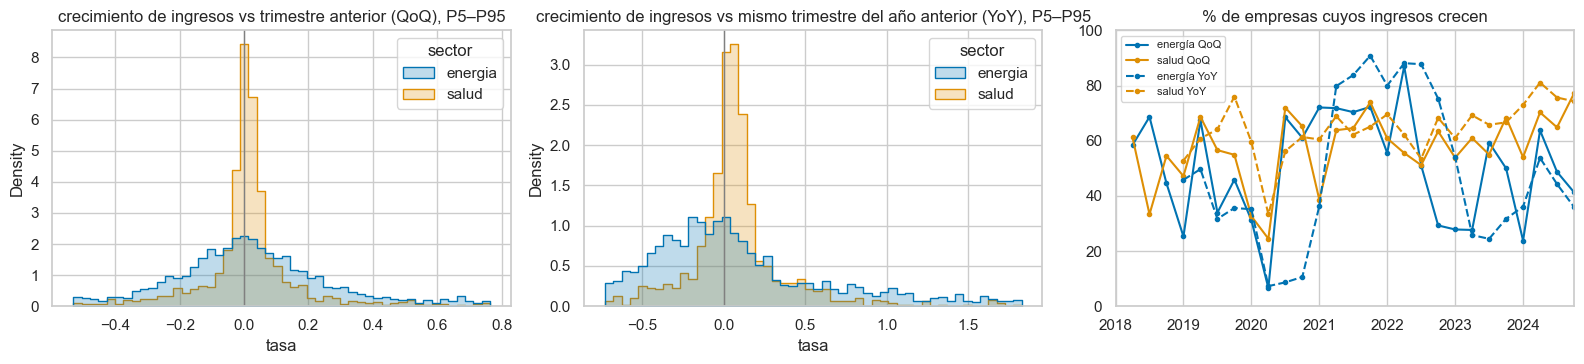

In [24]:
growth = panel[["sector", "trimestre", "ingresos_netos", "resultado_neto"]].copy()
for column in ["ingresos_netos", "resultado_neto"]:
    for lag in (1, 4):
        prev = lagged(panel, column, lag)
        growth[f"{column}_t-{lag}"] = prev
        # label only if both values exist; the rate only if the previous value is positive
        valid = growth[column].notna() & ~np.isnan(prev)
        growth[f"crece_{column}_{lag}"] = (growth[column] > prev).astype(float).where(valid)
        if column == "ingresos_netos":
            growth[f"tasa_{lag}"] = ((growth[column] - prev) / prev).where(valid & (prev > 0))

label_columns = [c for c in growth if c.startswith("crece_")]
availability = (
    growth[label_columns].notna().groupby(growth["sector"]).mean() * 100
).round(1).T.rename(columns=lambda s: f"% etiquetable {s}")
base = (growth.groupby("sector")[label_columns].mean() * 100).round(1).T.rename(
    columns=lambda s: f"% crece {s}"
)
for sector in SECTORS:
    summary[f"pct_crece_ingresos_qoq_{sector}"] = base.loc["crece_ingresos_netos_1", f"% crece {sector}"]
    summary[f"pct_crece_ingresos_yoy_{sector}"] = base.loc["crece_ingresos_netos_4", f"% crece {sector}"]
    summary[f"pct_etiquetable_ingresos_yoy_{sector}"] = availability.loc["crece_ingresos_netos_4", f"% etiquetable {sector}"]
display(pd.concat([availability, base], axis=1))

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, lag, name in zip(axes[:2], (1, 4), ("trimestre anterior (QoQ)", "mismo trimestre del año anterior (YoY)")):
    lo, hi = growth[f"tasa_{lag}"].quantile([0.05, 0.95])
    sns.histplot(
        data=growth[growth[f"tasa_{lag}"].between(lo, hi)], x=f"tasa_{lag}", hue="sector",
        palette=PALETTE, bins=50, stat="density", common_norm=False, element="step", ax=ax,
    )
    ax.axvline(0, color="gray", linewidth=1)
    ax.set_title(f"crecimiento de ingresos vs {name}, P5–P95")
    ax.set_xlabel("tasa")
plot_over_time(growth.assign(qoq=growth["crece_ingresos_netos_1"] * 100), "qoq", agg="mean",
               ax=axes[2], title="% de empresas cuyos ingresos crecen")
plot_over_time(growth.assign(yoy=growth["crece_ingresos_netos_4"] * 100), "yoy", agg="mean", ax=axes[2],
               title="% de empresas cuyos ingresos crecen")
axes[2].lines[2].set_linestyle("--")
axes[2].lines[3].set_linestyle("--")
axes[2].legend(["energía QoQ", "salud QoQ", "energía YoY", "salud YoY"], fontsize=8)
axes[2].set_ylim(0, 100)
plt.tight_layout()
plt.show()

## 8. Objetivo 3: quiebras

**Qué se mira.** Cuántas quiebras hay por sector y año; cuántas filas quedan etiquetadas como positivas con cada horizonte del rumbo (`quiebra_2t`: la empresa quiebra en los 2 trimestres siguientes; `quiebra_1a`: en los 4 siguientes); cuánto antes de la quiebra la empresa deja de presentar (brecha entre su último trimestre con fila y el trimestre de la quiebra); y si los ratios ya son distintos en los 4 trimestres previos a la quiebra.

**Por qué.** Define el desbalance de clases del objetivo 3 y cuántos positivos hay para entrenar. La brecha importa porque, si una empresa deja de presentar un año antes de quebrar, el modelo no tiene datos recientes justo cuando más los necesita. Y la comparación de ratios anticipa si las variables del rumbo tienen señal.

**Conclusión.** Hay **54 quiebras observables: 46 de energía y 8 de salud** (`04_build_panel` cuenta 55; la de EXCO Resources cae en 2018Q1 y no deja filas). Casi la mitad es de 2020 (25, de las cuales 22 de energía). Las etiquetas quedan muy desbalanceadas: `quiebra_2t` tiene 84 filas positivas (74 de energía, 1,8 % de sus filas, y 10 de salud, 0,6 %) y `quiebra_1a` tiene 172 (150, 3,6 %, y 22, 1,3 %). Con 8 quiebras, salud no alcanza para un modelo propio: hay que modelar los dos sectores juntos, con el sector como variable, y evaluar con métricas para clases desbalanceadas (área bajo la curva precisión-recall, recall de la clase positiva), no con exactitud.

Las empresas presentan hasta el final: en el **74 % de las quiebras la última fila es el trimestre inmediatamente anterior** (brecha de 1 trimestre) y la mediana de la brecha es 1. Unas pocas dejaron de presentar entre 1 y 3 años antes. El modelo tiene datos recientes para casi todas.

Los ratios del rumbo tienen señal, y es grande. En los 4 trimestres previos a la quiebra, comparado con las filas de empresas que no quiebran: el endeudamiento mediano es 0,87 contra 0,45 en energía y 1,18 contra 0,57 en salud (más de 1 significa pasivos mayores que activos, es decir, patrimonio negativo); la liquidez corriente es 0,64 contra 1,19 y 0,26 contra 1,44; el ROA trimestral es −3,8 % contra −0,1 % y −24 % contra 0. El flujo de caja operativo sobre ingresos discrimina poco en energía (0,21 contra 0,33). En salud, las empresas que van a quebrar ya muestran deterioro más de 4 trimestres antes; en energía no, porque las quiebras de 2020 fueron un shock rápido.

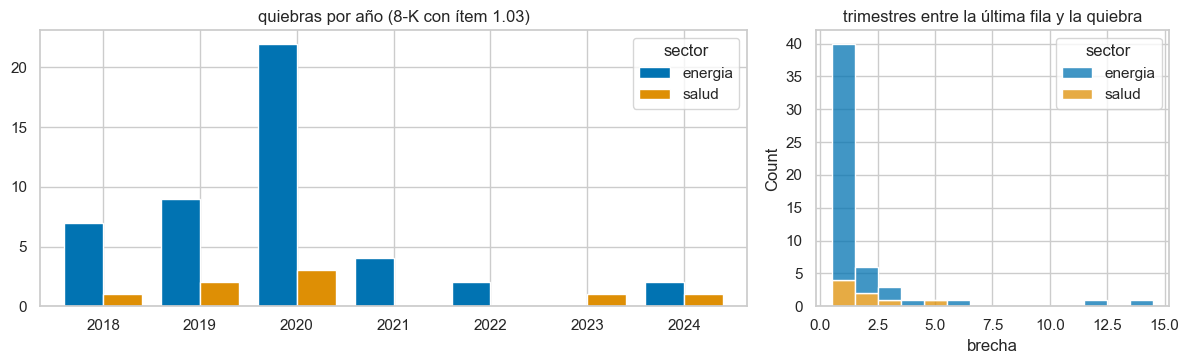

fecha_quiebra,2018,2019,2020,2021,2022,2023,2024
sector,,,,,,,
energia,7,9,22,4,2,0,2
salud,1,2,3,0,0,1,1
total,8,11,25,4,2,1,3


,quiebra_2t (filas),quiebra_2t (%),quiebra_1a (filas),quiebra_1a (%)
sector,,,,
energia,74,1.79,150,3.63
salud,10,0.59,22,1.30


In [25]:
companies = panel.groupby("cik").agg(
    sector=("sector", "first"),
    nombre=("nombre", "last"),
    fecha_quiebra=("fecha_quiebra", "first"),
    primero=("trimestre", "min"),
    ultimo=("trimestre", "max"),
    filas=("trimestre", "size"),
)
companies["q_quiebra"] = companies["fecha_quiebra"].dt.to_period("Q")
bankrupt = companies[companies["fecha_quiebra"].notna()].copy()
bankrupt["brecha"] = quarter_index(bankrupt["q_quiebra"]) - quarter_index(bankrupt["ultimo"])
summary["quiebras"] = len(bankrupt)
for sector in SECTORS:
    summary[f"quiebras_{sector}"] = int((bankrupt["sector"] == sector).sum())
summary["brecha_mediana_trimestres"] = float(bankrupt["brecha"].median())
summary["pct_quiebras_brecha_1"] = round((bankrupt["brecha"] == 1).mean() * 100, 1)

by_year = pd.crosstab(bankrupt["fecha_quiebra"].dt.year, bankrupt["sector"])
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), width_ratios=[2, 1])
by_year.plot.bar(ax=axes[0], color=[PALETTE[s] for s in by_year.columns], width=0.8)
axes[0].set_title("quiebras por año (8-K con ítem 1.03)")
axes[0].set_xlabel("")
plt.setp(axes[0].get_xticklabels(), rotation=0)
sns.histplot(data=bankrupt, x="brecha", hue="sector", palette=PALETTE, discrete=True,
             multiple="stack", ax=axes[1])
axes[1].set_title("trimestres entre la última fila y la quiebra")
plt.tight_layout()
plt.show()

panel["quiebra_2t"] = bankruptcy_within(panel, 2)
panel["quiebra_1a"] = bankruptcy_within(panel, 4)
positives = panel.groupby("sector")[["quiebra_2t", "quiebra_1a"]].agg(["sum", "mean"])
positives.columns = [f"{label} ({'filas' if stat == 'sum' else '%'})" for label, stat in positives.columns]
positives.iloc[:, [1, 3]] = (positives.iloc[:, [1, 3]] * 100).round(2)
for sector in SECTORS:
    summary[f"positivos_quiebra_2t_{sector}"] = int(positives.loc[sector, "quiebra_2t (filas)"])
    summary[f"positivos_quiebra_1a_{sector}"] = int(positives.loc[sector, "quiebra_1a (filas)"])
display(by_year.assign(total=by_year.sum(axis=1)).T)
positives

endeudamiento  liquidez_corriente  \
sector  grupo                                                                   
energia no quiebra                                  0.450               1.187   
        quiebra, más de 4 trimestres antes          0.532               0.780   
        ≤ 4 trimestres antes de quebrar             0.872               0.637   
salud   no quiebra                                  0.566               1.444   
        quiebra, más de 4 trimestres antes          0.502               2.899   
        ≤ 4 trimestres antes de quebrar             1.183               0.260   

                                              roa  fco_ingresos  
sector  grupo                                                    
energia no quiebra                         -0.001         0.325  
        quiebra, más de 4 trimestres antes -0.012         0.190  
        ≤ 4 trimestres antes de quebrar    -0.038         0.210  
salud   no quiebra                         -0.000         0.063  
        quiebra, más de 4 trimestres antes -0.099        -0.788  
        ≤ 4 trimestres antes de quebrar    -0.239        -0.362

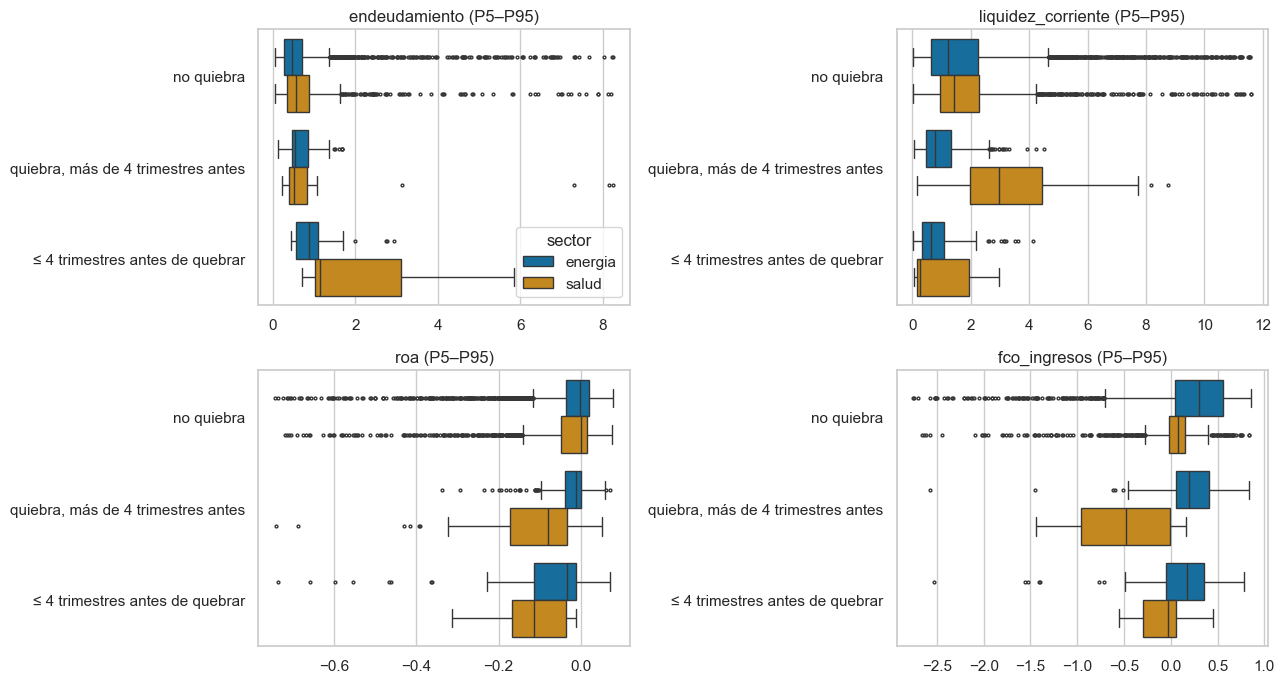

In [26]:
# ratios in the 4 quarters before a bankruptcy vs the rest
panel["t_hasta_quiebra"] = quarter_index(panel["fecha_quiebra"].dt.to_period("Q")) - quarter_index(panel["trimestre"])
panel["grupo"] = np.select(
    [panel["t_hasta_quiebra"] <= 4, panel["fecha_quiebra"].notna()],
    ["≤ 4 trimestres antes de quebrar", "quiebra, más de 4 trimestres antes"],
    "no quiebra",
)
PRE_RATIOS = ["endeudamiento", "liquidez_corriente", "roa", "fco_ingresos"]
medians = panel.groupby(["sector", "grupo"])[PRE_RATIOS].median().round(3)
display(medians)
for ratio in ["endeudamiento", "roa"]:
    for sector in SECTORS:
        summary[f"mediana_{ratio}_pre_quiebra_{sector}"] = medians.loc[(sector, "≤ 4 trimestres antes de quebrar"), ratio]
        summary[f"mediana_{ratio}_no_quiebra_{sector}"] = medians.loc[(sector, "no quiebra"), ratio]

fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for ax, ratio in zip(axes.flat, PRE_RATIOS):
    lo, hi = panel[ratio].quantile([0.05, 0.95])
    sns.boxplot(
        data=panel[panel[ratio].between(lo, hi)], x=ratio, y="grupo", hue="sector",
        palette=PALETTE, fliersize=2, ax=ax,
    )
    ax.set_title(f"{ratio} (P5–P95)")
    ax.set_ylabel("")
    ax.set_xlabel("")
    if ax is not axes.flat[0]:
        ax.get_legend().remove()
plt.tight_layout()
plt.show()

## 9. Salidas sin quiebra y desfasaje de presentación

**Qué se mira.** Primero, el estado final de cada empresa: quiebra, salida sin quiebra (su última fila es anterior a 2024Q4 y no tiene `fecha_quiebra`) o activa en 2024Q4; cuándo salen, si tienen huecos intermedios y cómo estaban sus ratios en su última fila. Después, el atraso entre el fin del trimestre y `fecha_presentacion`, y cuántas filas se conocieron **después del fin del trimestre siguiente** (`conocida_tarde`): esas filas no estaban disponibles al momento de predecir el trimestre siguiente.

**Por qué.** Una empresa que sale sin quebrar (comprada, fusionada, o que dejó de presentar a la SEC) no es un "no quiebra" en el futuro: después de su última fila no se sabe qué pasó, y el modelo no debe tratarla como superviviente (`TODO.md`: salidas que no son quiebra). El atraso es la pregunta del checklist sobre el desfasaje entre cierre y presentación, y mide el sesgo de anticipación de la regla de enmiendas (`docs/decisions.md`, sección 8): `fecha_presentacion` es el `filed` más reciente entre los números de la fila, así que basta con un valor corregido más tarde para que toda la fila cuente como conocida tarde. La medida es conservadora.

**Conclusión.** *Salidas.* **145 empresas (112 de energía y 33 de salud, el 44 % del panel) dejan el panel sin quiebra**, casi el triple que las quiebras (54); 132 llegan activas a 2024Q4. En energía, las salidas sin quiebra se concentran en 2018–2020 (32, 19 y 17 empresas). Solo 9 empresas tienen trimestres faltantes entre su primera y su última fila: las salidas son definitivas, no huecos. En su última fila, las que salen están a mitad de camino entre las activas y las quebradas: en energía, endeudamiento mediano 0,69 (activas 0,39, quiebras 1,03) y liquidez corriente 0,69 (1,64 y 0,33), y son más chicas (activos de 10^8,0 contra 10^8,8). Una parte son compras y fusiones, y otra parte son quiebras no captadas (empresas que dejan de presentar antes del 8-K, o que se dan de baja de la SEC con un Form 15). Para el objetivo 3 son casos **censurados**: después de su última fila no se sabe qué pasó, y tratarlas como "no quiebra" contamina la clase negativa con empresas en problemas.

*Atraso.* La distribución tiene los picos esperables en 40–50 días (10-Q) y 60–90 días (10-K, cuarto trimestre), pero el pico principal está en **unos 400 días: la mediana es 410 y el 88 % de las filas de 2018–2023 se conoció después del trimestre siguiente**. En 2024 es solo el 8 %. No es que las empresas presenten tarde: es la regla de versiones (`docs/decisions.md`, sección 8). Con "la última versión presentada hasta el 31/12/2023", el valor elegido para un trimestre suele ser el comparativo que vuelve a aparecer un año después (el 10-Q del mismo trimestre del año siguiente, o el 10-K siguiente), y `fecha_presentacion` toma ese `filed`. En 2024 se usa la primera versión y el atraso vuelve a ser el real.

Consecuencias: (1) tal como está, `fecha_presentacion` no sirve para filtrar "lo que se conocía en la fecha t": excluiría el 88 % de las filas; (2) el sesgo de anticipación es sistemático en 2018–2023, aunque en la mayoría de los casos el comparativo repite el valor original (en la prueba anterior difería el 6,4 % de los números).

**Propuesta.** (1) Que `02_build_dataset.ipynb` guarde también el `filed` de la **primera** versión de cada número y que el panel lleve las dos fechas: la foto al 31/12/2023 para los valores y la primera presentación para la disponibilidad. (2) Mientras tanto, entrenar con las variables rezagadas un trimestre (la fila t−1 para predecir en t), que cubre el atraso real de 40–90 días. (3) Para las salidas sin quiebra, dejar vacía la etiqueta de quiebra en los trimestres cuyo horizonte excede la última fila de la empresa, e identificar la causa de la salida con la API de la SEC (8-K con ítem 2.01, Form 15, Form 25), que está pendiente en `TODO.md`.

sector,energia,salud,total
estado,,,
activa en 2024Q4,87,45,132
quiebra,46,8,54
salida sin quiebra,112,33,145


empresas con trimestres faltantes entre su primera y su última fila: 9


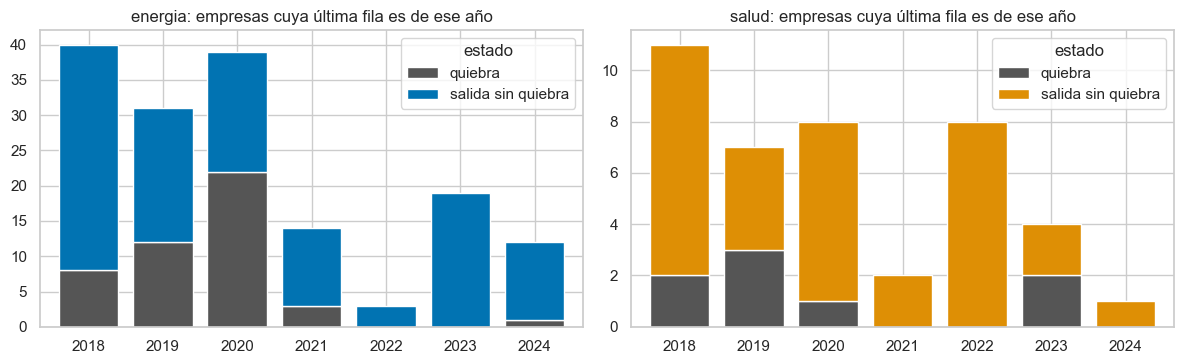

log10_activos  endeudamiento  liquidez_corriente  \
sector  estado                                                                 
energia activa en 2024Q4            8.782          0.393               1.640   
        quiebra                     8.928          1.028               0.331   
        salida sin quiebra          7.992          0.686               0.685   
salud   activa en 2024Q4            9.114          0.532               1.557   
        quiebra                     8.050          1.210               0.246   
        salida sin quiebra          8.043          0.841               1.437   

                              roa  
sector  estado                     
energia activa en 2024Q4    0.006  
        quiebra            -0.068  
        salida sin quiebra -0.021  
salud   activa en 2024Q4    0.004  
        quiebra            -0.166  
        salida sin quiebra -0.025

In [27]:
companies["estado"] = np.select(
    [companies["fecha_quiebra"].notna(), companies["ultimo"] < END],
    ["quiebra", "salida sin quiebra"],
    "activa en 2024Q4",
)
companies["huecos"] = (
    quarter_index(companies["ultimo"]) - quarter_index(companies["primero"]) + 1 - companies["filas"]
)
status = pd.crosstab(companies["estado"], companies["sector"])
status["total"] = status.sum(axis=1)
for estado, row in status.iterrows():
    summary[f"empresas_{estado.replace(' ', '_')}"] = int(row["total"])
summary["empresas_con_huecos"] = int((companies["huecos"] > 0).sum())
display(status)
print(f"empresas con trimestres faltantes entre su primera y su última fila: {(companies['huecos'] > 0).sum()}")

exits = companies[companies["estado"] != "activa en 2024Q4"]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, sector in zip(axes, SECTORS):
    by_year = pd.crosstab(exits.loc[exits["sector"] == sector, "ultimo"].dt.year,
                          exits.loc[exits["sector"] == sector, "estado"])
    by_year.plot.bar(stacked=True, ax=ax, color=["#555555", PALETTE[sector]], width=0.8)
    ax.set_title(f"{sector}: empresas cuya última fila es de ese año")
    ax.set_xlabel("")
    plt.setp(ax.get_xticklabels(), rotation=0)
plt.tight_layout()
plt.show()

# how were they doing in their last row?
last_rows = panel.loc[panel.groupby("cik")["trimestre"].idxmax()].set_index("cik")
last_rows["estado"] = companies["estado"]
last_rows["log10_activos"] = log10_positive(last_rows["activos_totales"])
last_rows.groupby(["sector", "estado"])[["log10_activos", "endeudamiento", "liquidez_corriente", "roa"]].median().round(3)

filas con atraso negativo (presentada antes del fin del trimestre): 0


,filas,pct_nan,min,P1,P5,P25,P50,P75,P95,P99,max
sector,,,,,,,,,,,
energia,4128,0.0,9,24.0,33.0,209.0,410.0,582.0,817.0,1152.0,1564
salud,1686,0.0,12,26.0,34.0,143.0,410.0,564.0,799.0,1154.0,1202


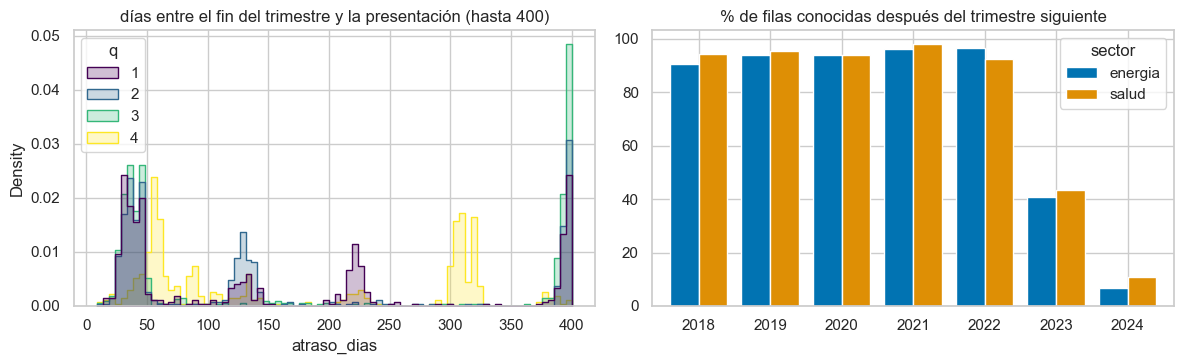

q,1,2,3,4
atraso mediano (días),458.0,435.0,402.0,456.5


sector,energia,salud
anio,,
2018,90.8,94.2
2019,93.9,95.4
2020,93.9,94.1
2021,96.3,98.3
2022,96.7,92.6
2023,40.7,43.4
2024,6.9,10.9


In [28]:
quarter_end = panel["trimestre"].dt.end_time.dt.normalize()
panel["atraso_dias"] = (panel["fecha_presentacion"] - quarter_end).dt.days
panel["conocida_tarde"] = panel["fecha_presentacion"] > (panel["trimestre"] + 1).dt.end_time

print(f"filas con atraso negativo (presentada antes del fin del trimestre): {(panel['atraso_dias'] < 0).sum()}")
display(describe_by_sector(panel, "atraso_dias").round(0))
by_q = panel.groupby("q")["atraso_dias"].median().rename("atraso mediano (días)")
summary["atraso_mediano_q1a3"] = float(panel.loc[panel["q"] < 4, "atraso_dias"].median())
summary["atraso_mediano_q4"] = float(by_q[4])
summary["pct_atraso_mayor_90"] = round((panel["atraso_dias"] > 90).mean() * 100, 1)

late = (panel.groupby(["anio", "sector"])["conocida_tarde"].mean().unstack("sector") * 100).round(1)
summary["pct_conocida_tarde_2018_2023"] = round(panel.loc[panel["anio"] <= 2023, "conocida_tarde"].mean() * 100, 1)
summary["pct_conocida_tarde_2024"] = round(panel.loc[panel["anio"] == 2024, "conocida_tarde"].mean() * 100, 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
sns.histplot(
    data=panel[panel["atraso_dias"].between(0, 400)], x="atraso_dias", hue="q", palette="viridis",
    bins=80, element="step", stat="density", common_norm=False, ax=axes[0],
)
axes[0].set_title("días entre el fin del trimestre y la presentación (hasta 400)")
late.plot.bar(ax=axes[1], color=[PALETTE[s] for s in late.columns], width=0.8)
axes[1].set_title("% de filas conocidas después del trimestre siguiente")
axes[1].set_xlabel("")
plt.setp(axes[1].get_xticklabels(), rotation=0)
plt.tight_layout()
plt.show()
display(by_q.to_frame().T)
late

## 10. Correlación entre ratios y resumen para el informe

**Qué se mira.** La correlación de Spearman (por rangos, robusta a los extremos de la sección 5) entre los 8 ratios y el tamaño (`log10` de activos), por sector.

**Por qué.** Dos ratios muy correlacionados aportan casi lo mismo al modelo, y la correlación con el tamaño muestra qué ratios en realidad miden "empresa chica".

**Conclusión.** ROA, margen neto y margen operativo ordenan a las empresas casi igual: Spearman de 0,93–0,94 entre ROA y margen neto y de 0,78–0,86 con el margen operativo, en los dos sectores. Comparten el numerador y el orden lo domina el signo del resultado. Endeudamiento y liquidez corriente están fuertemente anticorrelacionados (−0,74 y −0,81). El ROE se correlaciona poco con todo (0,25–0,35 con el ROA), consecuencia del signo engañoso con patrimonio negativo (sección 5). El margen bruto no se correlaciona con nada y además tiene poca cobertura. El tamaño se asocia con la rentabilidad en salud (0,49 con el ROA y 0,52 con el margen operativo) y menos en energía (0,28–0,31): las empresas chicas son las que pierden.

**Propuesta.** En modelos lineales, usar un ratio por grupo (ROA; endeudamiento o liquidez; FCO/ingresos) más el tamaño (`log10` de activos) y el sector. Los modelos de árboles toleran la redundancia y pueden usar todos.

energia, pares con mayor |rho|:
margen_neto       roa                 0.93
                  margen_operativo    0.83
margen_operativo  roa                 0.78 



salud, pares con mayor |rho|:
margen_neto       roa                 0.94
                  margen_operativo    0.86
margen_operativo  roa                 0.81 



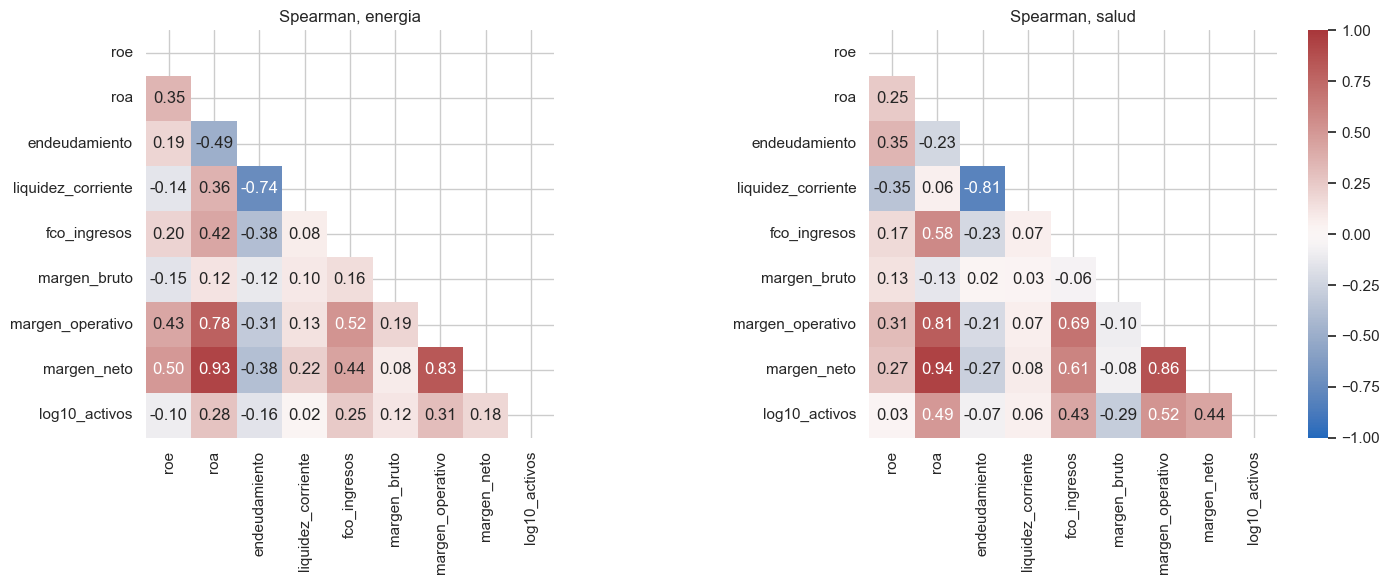

In [29]:
corr_columns = RATIO_COLUMNS + ["log10_activos"]
data = panel.assign(log10_activos=log10_positive(panel["activos_totales"]))
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, sector in zip(axes, SECTORS):
    corr = data.loc[data["sector"] == sector, corr_columns].corr(method="spearman")
    mask = np.triu(np.ones_like(corr, dtype=bool))
    sns.heatmap(corr, mask=mask, vmin=-1, vmax=1, cmap="vlag", annot=True, fmt=".2f",
                square=True, cbar=ax is axes[-1], ax=ax)
    ax.set_title(f"Spearman, {sector}")
    pairs = corr.where(~mask).stack()
    strongest = pairs.reindex(pairs.abs().sort_values(ascending=False).index).head(3)
    print(f"{sector}, pares con mayor |rho|:")
    print(strongest.round(2).to_string(), "\n")
plt.tight_layout()
plt.show()

### Resumen para el informe

| Pregunta del checklist de la mentora | Sección | Respuesta corta |
|---|---|---|
| ¿Cuántas empresas tienen datos completos y cómo se tratan los parciales? | 2 | 18 de 331 empresas tienen los 11 conceptos en todas sus filas; 220 tienen completos resultado neto e ingresos. Se conservan las filas parciales (panel no balanceado) y los faltantes quedan como vacíos. `pasivos_totales` cubre el 77 % y `margen_bruto` el 15 %. |
| ¿Qué umbral de outliers se usa en cada ratio y se aplica igual en los dos sectores? | 5 | Márgenes fuera de (−5, 2) y endeudamiento mayor a 5 (guía); ROA fuera de (−1, 1), ROE fuera de (−5, 5), liquidez corriente mayor a 50, FCO/ingresos fuera de (−5, 5) (propuesta). Marca 698 filas (12 %) de 142 empresas; el 80 % de esas filas tiene ingresos o activos menores a 1 millón de USD. Propuesta: mismo umbral en los dos sectores, marcar sin borrar. |
| ¿Cómo se maneja el desfasaje entre cierre y presentación? | 9 | `fecha_presentacion` es el `filed` más reciente de la fila. Por la regla de versiones, la mediana es de 410 días y el 88 % de 2018–2023 se conoció después del trimestre siguiente. Propuesta: guardar también la primera presentación y entrenar con rezago de 1 trimestre. |
| ¿Se verificaron las unidades con una empresa conocida? | 3 | HCA Healthcare y Occidental Petroleum, 2023: coinciden con sus 10-K al millón de USD. Los valores están en USD. |

Propuestas que quedan pendientes de decisión del grupo (ninguna está aplicada en el panel):

1. **Outliers** (sección 5): umbrales fijos iguales en los dos sectores; bandera `outlier` por fila en lugar de borrar; bandera `empresa_minuscula` (ingresos o activos menores a 1 millón de USD); recortar solo al entrenar modelos sensibles a la escala.
2. **ROE** (sección 5): vacío cuando el patrimonio es ≤ 0, con bandera `patrimonio_negativo`; ROA como rentabilidad principal.
3. **Cobertura** (sección 2): revisar los tags de ingresos y resultado operativo (faltan en 1 de cada 6 filas); evaluar reconstruir `pasivos_totales` como activos − patrimonio con bandera; descartar `margen_bruto` o usarlo solo en salud.
4. **Fecha de disponibilidad** (sección 9): guardar el `filed` de la primera versión de cada número en `02_build_dataset.ipynb` y llevarlo al panel; mientras tanto, variables rezagadas un trimestre.
5. **Salidas sin quiebra** (sección 9): etiqueta de quiebra vacía cuando el horizonte excede la última fila; identificar la causa con la API de la SEC.
6. **Objetivo 2** (sección 7): crecimiento de ingresos interanual (YoY).
7. **Objetivo 3** (sección 8): un solo modelo para los dos sectores, con métricas para clases desbalanceadas.
8. **Variables** (secciones 6 y 10): incluir el año o el shock de 2020, el trimestre del año, el sector y el tamaño; en modelos lineales, un ratio por grupo.

In [30]:
pd.set_option("display.max_rows", 200)
pd.Series(summary, name="valor").to_frame()

,valor
filas,5814.0000
empresas,331.0000
empresas_energia,245.0000
empresas_salud,86.0000
pct_empresas_28_trimestres_energia,33.9000
pct_empresas_28_trimestres_salud,51.2000
activas_2024Q4_energia,87.0000
activas_2024Q4_salud,45.0000
cobertura_ganancia_bruta_energia,10.6000
cobertura_ganancia_bruta_salud,34.4000
